In [1]:
%pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn pillow scipy pyarrow imagehash pyyaml

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys

sys.path.insert(0, "..")  # pipeline.py e prepare_data.py ficam na raiz do projeto

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers, ops, applications, callbacks, losses, metrics, optimizers

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)

from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, HAM_CLASSES, load_labels
from pipeline import CLASS_IDX, HAM_IDX, augment, build_cache, center_crop, decode, make_ds, simular_celular

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026101904


GPUs: []


In [3]:
# Parâmetros de decisão do modelo de pintas (modelos/pintas/README.md), usados na rota de pintas
PRIOR = np.array([910, 6384, 3145, 275, 4981, 6000, 1460, 280], dtype=float)  # classes no treino, ordem de CLASSES
LOG_PRIOR = np.log(PRIOR / PRIOR.sum())
TAU, LIMIAR_MALIGNO = 1.1, 0.287

# Triagem de erupções, alergias e queimaduras (pausada)

> Parte do projeto **pausada** para focar no modelo de pintas (`../notebook.ipynb`). Continua executável a partir desta pasta.

## Triagem em duas etapas

O modelo de pintas classifica lesões em dermatoscopia e em foto de celular. Esta triagem o amplia para **erupções, alergias e infecções de pele em fotos de celular**, e dá uma orientação de próximo passo para cada caso.

**Este é um projeto acadêmico de apoio à triagem. O resultado é sempre uma sugestão ou orientação, nunca um diagnóstico.**

Para rodar esta parte, é preciso ter a pasta `data_Alergias` (SCIN) ao lado do repositório e a base de pintas do README principal. O PAD-UFES-20 é baixado automaticamente, e as redes treinadas já vêm em `modelos/triagem/`, então o treino é pulado.

| Etapa | O que é feito |
|---|---|
| 1. Exploração | entender o SCIN: colunas, rótulos, classes, tipos de pele |
| 2. Limpeza | extrair imagens, remover duplicatas e casos sem rótulo confiável |
| 3. Splits | treino, validação e teste por caso, sem vazamento |
| PAD-UFES-20 | fotos de celular de pintas, que faltavam no SCIN |
| 4. Arquitetura e treino | detector de tipo de foto, roteador e especialista |
| 5. Orientação | urgência e perguntas de alerta, só por regras |
| 6. Avaliação | métricas no teste, erro grave, calibração, tipo de pele, Grad-CAM |

In [4]:
import ast
from collections import Counter
import glob
import hashlib
import io
import json
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache

import imagehash
import pyarrow.parquet as pq
import yaml
from IPython.display import display
from PIL import ImageOps, UnidentifiedImageError
from scipy.optimize import minimize_scalar
from scipy.special import softmax as scipy_softmax
from sklearn.metrics import recall_score
from sklearn.model_selection import StratifiedGroupKFold

from pipeline import center_crop, decode, meta_features, shades_of_gray
from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, load_labels

SEED = 42
keras.utils.set_random_seed(SEED)

REPO = Path.cwd()       # esta pasta (triagem_alergias)
RAIZ = REPO.parent      # raiz do projeto
# dados brutos ficam ao lado do repositório; bases prontas e cache, em ~/datasets, fora do repositório
SCIN_RAW_DIR = Path(os.environ.get("SCIN_RAW", RAIZ.parent / "data_Alergias"))
SCIN_DIR = DEFAULT_DIR.parent / "scin"
PAD_RAW_DIR = DEFAULT_DIR.parent / "pad_ufes_raw"
PAD_DIR = DEFAULT_DIR.parent / "pad_ufes"
SPLITS = REPO / "splits"
SCIN_SPLITS, PAD_SPLITS = SPLITS / "scin_v1.csv", SPLITS / "pad_v1.csv"
MODELS = REPO / "modelos" / "triagem"       # as redes treinadas vêm no repositório
THRESHOLDS = MODELS / "limiares.json"
WORK_DIR = DEFAULT_DIR.parent / "modelos" / "triagem_treino"
RELATORIOS = REPO / "relatorios"
FIGURAS = RELATORIOS / "figuras"

BLUE, ORANGE = "#2a78d6", "#eb6834"
print("SCIN:", SCIN_RAW_DIR, "| modelos:", MODELS)

SCIN: C:\Users\felip\OneDrive\Documentos\InsperAI\ProjetoFinal\data_Alergias | modelos: C:\Users\felip\OneDrive\Documentos\InsperAI\ProjetoFinal\ProjetoFinal-InsperAI-FelipeGava-LucasBriones\triagem_alergias\modelos\triagem


## Etapa 1: exploração do SCIN (`data_Alergias`)

Base usada para ampliar a triagem para lesões além das pintas. **Este é um projeto acadêmico de apoio à triagem: o resultado é uma sugestão ou orientação, não um diagnóstico.**

### Conclusões

- **É o SCIN, do Google**, com imagens embutidas nos parquets, mas **falta um dos 26 arquivos** (`train-00000-of-00026.parquet`). Há 25 arquivos, 4.839 casos e 9.998 imagens.
- **Cada caso tem de 1 a 3 fotos de celular da mesma lesão** (39% têm 1; 45% têm 3). É por isso que a divisão treino/validação/teste é por `case_id`.
- **Há diagnóstico prévio em 61% dos casos** (2.947 com rótulo e 1.892 sem). Quase todos os casos sem rótulo foram marcados como sem qualidade de imagem suficiente.
- **Os rótulos são incertos.** Cada caso tem em média mais de uma condição possível: só 665 têm condição única, e o peso mediano da condição principal é 0,55. Em 886 casos há empate no topo. A confiança mediana dos dermatologistas é 2,5 de 5. Isso favorece testar **rótulos suaves**.
- **Cauda longa**: 205 condições como principal, só 20 com pelo menos 30 casos. Eczema, dermatite de contato, urticária e picada de inseto dominam.
- **Pele**: predominam tons claros (Monk 2 e 3), e os tons 8 a 10 são raros. Fitzpatrick falta em 50% dos casos e a idade em 57%. O desempenho em pele escura terá pouca evidência.
- **Queimaduras: praticamente não há** (32 citações, 7 como condição principal e só 4 casos depois da limpeza). A classe fica **desativada** até haver uma base específica.
- **Feridas: poucas** (40 como principal; 30 casos depois da limpeza). **Pintas: quase nenhuma** (22 como principal; 17 depois da limpeza). O SCIN não serve, sozinho, para ensinar o que é pinta.
- **Base limpa**: 5.434 imagens de 2.581 casos, em 16 condições + `outras_condicoes`.
- **Nenhuma duplicata** entre o SCIN e as bases de pintas (ISIC 2019/2018, HAM10000).

Todas as fotos são de pessoas reais, de-identificadas pelo Google. Os exemplos abaixo são só de close, em adultos, sem tronco nem região genital.

In [5]:
GROUP_TERMS = {
    "ferida": ("wound", "ulcer", "abrasion", "laceration", "traumatic blister"),   # vem antes: "friction burn" é ferida
    "queimadura": ("burn",),
    "pinta": ("melanocytic nevus", "atypical nevus", "melanoma", "lentigo", "basal cell", "squamous cell",
              "seborrheic keratosis", "actinic keratosis", "dysplastic nevus", "blue nevus", "keratoacanthoma"),
}


def group_of(condition):
    if condition is None or pd.isna(condition):
        return None
    name = condition.lower()
    for group, terms in GROUP_TERMS.items():
        if any(t in name for t in terms):
            return group
    return "erupcao_alergia"

In [6]:
# só as colunas de texto: as imagens embutidas ficam de fora, para não carregar 12 GB
files = sorted(SCIN_RAW_DIR.glob("*.parquet"))
faltando = sorted({f"train-{i:05d}-of-00026.parquet" for i in range(26)} - {f.name for f in files})
names = pq.ParquetFile(files[0]).schema_arrow.names
text_cols = [c for c in names if not (c.startswith("image_") and c.endswith("_path"))]
scin_bruto = pd.concat([pq.read_table(f, columns=text_cols).to_pandas() for f in files], ignore_index=True)
print(f"{len(files)} de 26 arquivos | faltando: {faltando}")
print(f"{len(scin_bruto)} casos, {scin_bruto['case_id'].nunique()} case_id únicos, {len(names)} colunas")

25 de 26 arquivos | faltando: ['train-00000-of-00026.parquet']
4839 casos, 4839 case_id únicos, 73 colunas


### Colunas

Cada linha é um **caso** (`case_id`), um envio feito por uma pessoa nos EUA, por fotos de celular, com até 3 imagens da mesma lesão.

In [7]:
grupos = {
    "Identificação": ["case_id", "source", "release", "year"],
    "Imagens (bytes + nome) e tipo de foto": [c for c in names if c.startswith("image_")],
    "Demografia autodeclarada": ["age_group", "sex_at_birth", "fitzpatrick_skin_type", "combined_race"]
        + [c for c in names if c.startswith("race_ethnicity_")],
    "Sintomas, textura, região do corpo e duração": [c for c in names if c.startswith(("textures_", "body_parts_", "condition_symptoms_", "other_symptoms_"))]
        + ["related_category", "condition_duration"],
    "Rótulos de dermatologistas (condição)": ["weighted_skin_condition_label", "dermatologist_skin_condition_on_label_name", "dermatologist_skin_condition_confidence"]
        + [c for c in names if c.startswith("dermatologist_gradable_for_skin")],
    "Tipo de pele avaliado por especialistas": [c for c in names if "fitzpatrick_skin_type_" in c and c.startswith("dermatologist")] + [c for c in names if "monk" in c],
}
pd.DataFrame({"grupo": grupos.keys(), "colunas": [len(v) for v in grupos.values()],
              "exemplos": [", ".join(v[:3]) for v in grupos.values()]})

,grupo,colunas,exemplos
0,Identificação,4,"case_id, source, release"
1,Imagens (bytes + nome) e tipo de foto,6,"image_1_path, image_2_path, image_3_path"
2,Demografia autodeclarada,14,"age_group, sex_at_birth, fitzpatrick_skin_type"
3,"Sintomas, textura, região do corpo e duração",33,"textures_raised_or_bumpy, textures_flat, textu..."
4,Rótulos de dermatologistas (condição),6,"weighted_skin_condition_label, dermatologist_s..."
5,Tipo de pele avaliado por especialistas,10,dermatologist_gradable_for_fitzpatrick_skin_ty...


### Há diagnóstico prévio?

Cada dermatologista indica até 3 condições, com confiança de 1 a 5. `weighted_skin_condition_label` junta tudo em pesos que somam 1 por caso: um caso pode ter várias condições possíveis.

Com rótulo de dermatologista: 2947 (60.9%) | sem rótulo: 1892
Condições possíveis por caso: {1: 665, 2: 775, 3: 1193, 4: 157, 5: 110, 6: 36, 7: 8, 8: 3}
Dermatologistas por caso: {1: 645, 2: 745, 3: 1116, 4: 125, 5: 114, 6: 106, 7: 59, 8: 28, 9: 9}
Peso da condição principal: mediana 0.55; casos com condição única: 665; empate no topo: 886


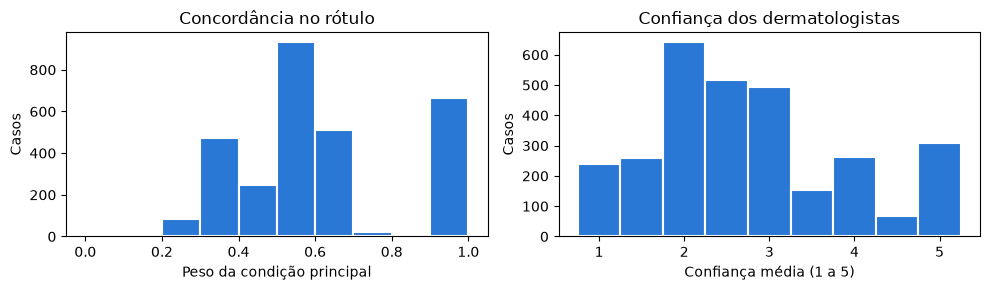

Avaliável (1º dermatologista): {'DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT': 2939, 'NO_IMAGE_QUALITY_INSUFFICIENT': 1843, 'YES_IMAGE_QUALITY_SUFFICIENT_NO_DISCERNIBLE_PATHOLOGY': 57}


In [8]:
pesos = scin_bruto["weighted_skin_condition_label"].map(ast.literal_eval)
conf = scin_bruto["dermatologist_skin_condition_confidence"].map(ast.literal_eval)
tem = pesos.map(len) > 0
print(f"Com rótulo de dermatologista: {tem.sum()} ({tem.mean():.1%}) | sem rótulo: {(~tem).sum()}")
print("Condições possíveis por caso:", pesos[tem].map(len).value_counts().sort_index().to_dict())
print("Dermatologistas por caso:", conf[tem].map(len).value_counts().sort_index().to_dict())

peso_max = pesos[tem].map(lambda d: max(d.values()))
conf_media = conf[tem].map(np.mean)
empates = pesos[tem].map(lambda d: sum(v == max(d.values()) for v in d.values()) > 1).sum()
print(f"Peso da condição principal: mediana {peso_max.median():.2f}; casos com condição única: {(peso_max == 1).sum()}; empate no topo: {empates}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
a1.hist(peso_max, bins=np.arange(0, 1.05, 0.1), color=BLUE, edgecolor="white", linewidth=1.5)
a1.set(xlabel="Peso da condição principal", ylabel="Casos", title="Concordância no rótulo")
a2.hist(conf_media, bins=np.arange(0.75, 5.5, 0.5), color=BLUE, edgecolor="white", linewidth=1.5)
a2.set(xlabel="Confiança média (1 a 5)", ylabel="Casos", title="Confiança dos dermatologistas")
plt.tight_layout(); plt.show()

aval = scin_bruto["dermatologist_gradable_for_skin_condition_1"].value_counts().to_dict()
print("Avaliável (1º dermatologista):", aval)

### Imagens por caso

In [9]:
shots = scin_bruto[[f"image_{i}_shot_type" for i in (1, 2, 3)]]
n = shots.notna().sum(axis=1)
print("Imagens por caso:", n.value_counts().sort_index().to_dict(), "| total:", int(n.sum()))
print("Tipo de foto:", pd.Series(shots.values.ravel()).value_counts().to_dict())

Imagens por caso: {1: 1871, 2: 775, 3: 2193} | total: 10000
Tipo de foto: {'CLOSE_UP': 4835, 'AT_AN_ANGLE': 2901, 'AT_DISTANCE': 2264}


### Distribuição das condições

Contagem pela condição de maior peso em cada caso.

205 condições como principal (363 com qualquer peso)
Com pelo menos 30 casos: 20 | 10 a 29: 26 | menos de 10: 159


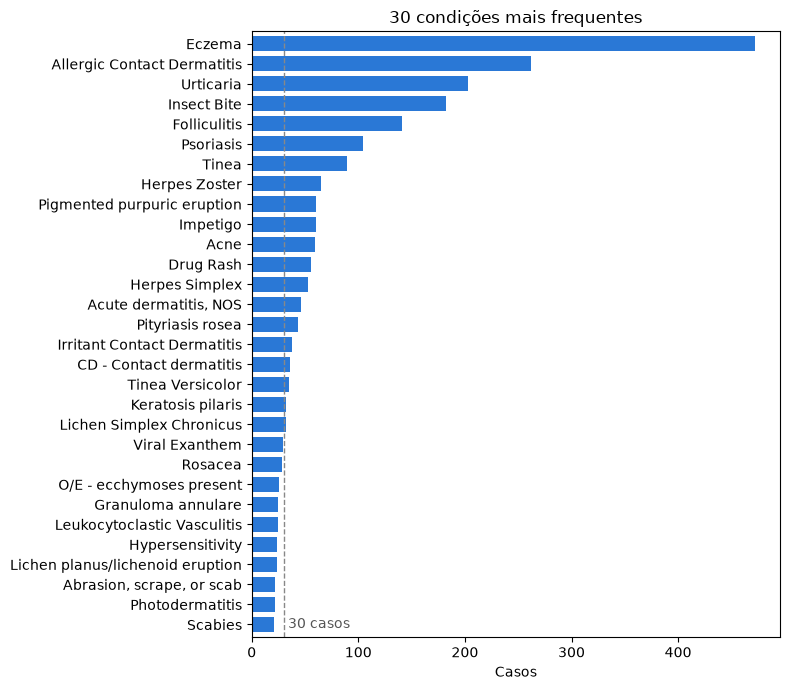

In [10]:
top = pesos[tem].map(lambda d: max(d, key=d.get))
vc = top.value_counts()
print(f"{len(vc)} condições como principal ({len(Counter(k for d in pesos for k in d))} com qualquer peso)")
print(f"Com pelo menos 30 casos: {(vc >= 30).sum()} | 10 a 29: {((vc >= 10) & (vc < 30)).sum()} | menos de 10: {(vc < 10).sum()}")

fig, ax = plt.subplots(figsize=(8, 7))
vc.head(30).iloc[::-1].plot.barh(ax=ax, color=BLUE, width=0.75)
ax.axvline(30, color="#888", linestyle="--", linewidth=1)
ax.text(34, 0, "30 casos", color="#555", va="center")
ax.grid(axis="y", visible=False)
ax.set(xlabel="Casos", ylabel="", title="30 condições mais frequentes")
plt.tight_layout(); plt.show()

### Tipo de pele, idade e sexo

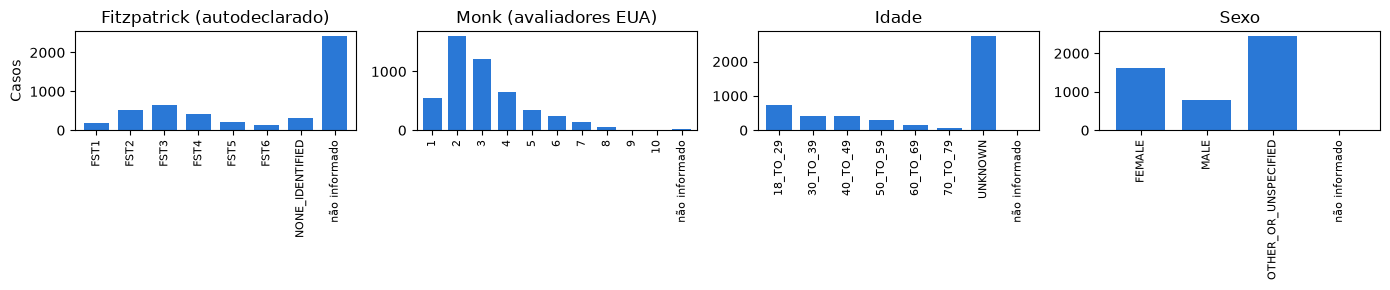

Sem Fitzpatrick: 50% | idade desconhecida: 57%


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
series = [("fitzpatrick_skin_type", "Fitzpatrick (autodeclarado)"), ("monk_skin_tone_label_us", "Monk (avaliadores EUA)"),
          ("age_group", "Idade"), ("sex_at_birth", "Sexo")]
for ax, (col, title) in zip(axes, series):
    s = scin_bruto[col].fillna("não informado").astype(str).str.replace("AGE_", "").str.replace(".0", "", regex=False)
    counts = s.value_counts().sort_index()
    if col == "monk_skin_tone_label_us":
        counts = counts.reindex(sorted(counts.index, key=lambda v: float(v) if v[0].isdigit() else 99))
    counts.plot.bar(ax=ax, color=BLUE, width=0.75)
    ax.grid(axis="x", visible=False)
    ax.set(title=title, xlabel="", ylabel="Casos" if ax is axes[0] else "")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print("Sem Fitzpatrick:", f"{scin_bruto['fitzpatrick_skin_type'].isna().mean():.0%}", "| idade desconhecida:", f"{(scin_bruto['age_group'] == 'AGE_UNKNOWN').mean():.0%}")

### Há queimaduras, feridas ou pintas?

Termos procurados em todas as condições citadas, inclusive as de menor peso. O grupo vem de `clean_scin.group_of`.

In [12]:
linhas = []
for d in pesos:
    for k, v in d.items():
        g = group_of(k)
        if g != "erupcao_alergia":
            linhas.append({"grupo": g, "condicao": k, "peso": v, "principal": k == max(d, key=d.get)})
t = pd.DataFrame(linhas)
resumo = t.groupby("grupo").agg(casos_citados=("condicao", "size"), casos_como_principal=("principal", "sum"), condicoes=("condicao", "nunique"))
display(resumo)
for g, s in t.groupby("grupo"):
    print(g, "->", s["condicao"].value_counts().head(8).to_dict())

,casos_citados,casos_como_principal,condicoes
grupo,,,
ferida,82,40,18
pinta,66,22,6
queimadura,32,7,9


ferida -> {'Abrasion, scrape, or scab': 46, 'Superficial wound of body region': 9, 'Animal bite - wound': 7, 'Foot ulcer': 2, 'Abrasion of wrist': 2, 'Skin ulcer': 2, 'Venous Stasis Ulcer': 2, 'Traumatic ulcer': 2}
pinta -> {'Actinic Keratosis': 20, 'Basal Cell Carcinoma': 19, 'Melanocytic Nevus': 12, 'Melanoma': 7, 'Atypical Nevus': 5, 'Lentigo': 3}
queimadura -> {'Burn of skin': 16, 'Sunburn': 6, 'Burn erythema of back of hand': 3, 'Burn erythema of lower leg': 2, 'Contact burn of skin': 1, 'Burn of forearm': 1, 'post-sunburn peeling/superficial desquamation': 1, 'Burn erythema of abdominal wall': 1}


## Etapa 2: limpeza dos dados

Cada imagem passa por uma sequência de filtros, e a tabela guarda o motivo de cada remoção. Tudo é reproduzível; a extração e os hashes ficam em cache, então rodar de novo leva poucos minutos.

**Limiares escolhidos**
- `MIN_SIDE`: lado menor de pelo menos 224 px, o tamanho de entrada da rede.
- `MIN_CONFIDENCE = 1,5`: remove os casos em que os dermatologistas estavam, em média, quase no mínimo de confiança (escala de 1 a 5).
- `MIN_CASES = 30`: condições com menos casos vão para `outras_condicoes`.
- **Quase-duplicatas**: pHash com distância até 12 gera candidatas, e a correlação dos pixels ≥ 0,98 confirma. Na revisão manual de pares, só o pHash marcava como iguais fotos de pessoas diferentes (com distância 4 ou 6), porque fotos de pele têm pouco detalhe.

In [13]:
MIN_SIDE = 224
NEAR_DUP_MAX = 12         # distância de Hamming máxima no pHash para ser candidata
NEAR_DUP_CORR = 0.98      # correlação mínima dos pixels (cinza, 64x64) para confirmar
MIN_CONFIDENCE = 1.5      # confiança média mínima dos dermatologistas (escala de 1 a 5)
MIN_CASES = 30            # classes com menos casos viram "outras_condicoes"
OTHER = "outras_condicoes"

# rótulos que os dermatologistas usam como sinônimos: os pesos são somados
SYNONYMS = {
    "Allergic Contact Dermatitis": "Contact Dermatitis",
    "Irritant Contact Dermatitis": "Contact Dermatitis",
    "CD - Contact dermatitis": "Contact Dermatitis",
    "Acute dermatitis, NOS": "Dermatitis, NOS",
    "Chronic dermatitis, NOS": "Dermatitis, NOS",
    "Acute and chronic dermatitis": "Dermatitis, NOS",
}
IMAGE_COLS = [f"image_{i}_path" for i in (1, 2, 3)]
GRADABLE_COLS = [f"dermatologist_gradable_for_skin_condition_{i}" for i in (1, 2, 3)]
META_COLS = ["case_id", "age_group", "sex_at_birth", "fitzpatrick_skin_type", "related_category",
             "condition_duration", "monk_skin_tone_label_us", "monk_skin_tone_label_india",
             "dermatologist_fitzpatrick_skin_type_label_1", "dermatologist_skin_condition_confidence",
             "weighted_skin_condition_label", *GRADABLE_COLS]

### Extração das imagens dos parquets

Cada imagem vira um JPEG em `~/datasets/scin/images/`. O hash MD5 é do arquivo PNG original.

In [14]:
def phash_hex(img) -> str:
    return str(imagehash.phash(img))


def to_uint64(hashes) -> np.ndarray:
    return np.array([int(h, 16) for h in hashes], dtype=np.uint64)


def read_ids(path: Path) -> pd.DataFrame:
    return pd.read_csv(path, dtype={"case_id": str, "image_id": str}, low_memory=False)


def extract_one(item, images_dir: Path) -> dict:
    """Grava o JPEG de uma imagem do parquet e devolve seus hashes (os bytes são o PNG original)."""
    case_id, num, shot, cell = item
    image_id = Path(cell["path"]).stem
    row = {"case_id": case_id, "image_id": image_id, "image_num": num, "shot_type": shot,
           "md5": hashlib.md5(cell["bytes"]).hexdigest(), "corrompida": False}
    try:
        img = Image.open(io.BytesIO(cell["bytes"]))
        img.load()
        img = img.convert("RGB")
    except (UnidentifiedImageError, OSError, ValueError):
        return {**row, "corrompida": True}
    dst = images_dir / f"{image_id}.jpg"
    if not dst.exists():
        tmp = dst.with_suffix(".tmp")
        img.save(tmp, "JPEG", quality=95)
        os.replace(tmp, dst)
    return {**row, "largura": img.width, "altura": img.height,
            "phash": phash_hex(img), "phash_espelho": phash_hex(ImageOps.mirror(img))}


def extrair_scin(raw_dir: Path, out_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Extrai as imagens de todos os parquets. Devolve (imagens, casos) e guarda em cache."""
    images_dir = out_dir / "images"
    images_dir.mkdir(parents=True, exist_ok=True)
    img_cache, case_cache = out_dir / "_imagens_brutas.csv", out_dir / "_casos_brutos.csv"
    if img_cache.exists() and case_cache.exists():
        return read_ids(img_cache), read_ids(case_cache)
    files = sorted(raw_dir.glob("*.parquet"))
    if not files:
        sys.exit(f"Nenhum parquet em {raw_dir}")
    columns = META_COLS + IMAGE_COLS + [f"image_{i}_shot_type" for i in (1, 2, 3)]
    rows, cases = [], []
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        for n, f in enumerate(files, 1):
            for batch in pq.ParquetFile(f).iter_batches(batch_size=16, columns=columns):
                items = []
                for rec in batch.to_pylist():
                    cases.append({k: rec[k] for k in META_COLS})
                    items += [(rec["case_id"], i, rec[f"image_{i}_shot_type"], rec[f"image_{i}_path"])
                              for i in (1, 2, 3) if rec[f"image_{i}_path"] and rec[f"image_{i}_path"]["bytes"]]
                rows += list(pool.map(lambda it: extract_one(it, images_dir), items))
            print(f"[{n}/{len(files)}] {f.name}: {len(rows)} imagens", flush=True)
    pd.DataFrame(rows).to_csv(img_cache, index=False)
    pd.DataFrame(cases).to_csv(case_cache, index=False)
    return read_ids(img_cache), read_ids(case_cache)

### Duplicatas

Exatas por MD5 e quase-duplicatas por pHash + correlação, inclusive espelhadas. A checagem entre bases compara cada imagem do SCIN com as 33.568 imagens das bases de pintas, para não haver vazamento entre treino e teste.

In [15]:
def gray(path, mirror=False) -> np.ndarray:
    img = Image.open(path).convert("L").resize((64, 64))
    return np.asarray(ImageOps.mirror(img) if mirror else img, dtype=np.float32).ravel()


def confirmed(path_a, path_b, mirror: bool) -> bool:
    a, b = gray(path_a), gray(path_b, mirror)
    return a.std() > 0 and b.std() > 0 and np.corrcoef(a, b)[0, 1] >= NEAR_DUP_CORR


def near_duplicates(images: pd.DataFrame, images_dir: Path) -> set:
    """Índices a remover: de cada par confirmado, fica a primeira imagem da tabela."""
    h, flip = to_uint64(images["phash"]), to_uint64(images["phash_espelho"])
    ids, index = images["image_id"].values, images.index.values
    path = lambda k: images_dir / f"{ids[k]}.jpg"
    drop = set()
    for i in range(len(h) - 1):
        if index[i] in drop:
            continue
        direct = np.bitwise_count(h[i + 1:] ^ h[i])
        mirrored = np.bitwise_count(h[i + 1:] ^ flip[i])
        for off in np.where(np.minimum(direct, mirrored) <= NEAR_DUP_MAX)[0]:
            j = i + 1 + off
            if index[j] not in drop and confirmed(path(i), path(j), bool(mirrored[off] < direct[off])):
                drop.add(index[j])
    return drop


def lesion_phashes(out_dir: Path) -> pd.DataFrame:
    """pHash das imagens das bases de pintas (com cache: são 33 mil arquivos)."""
    cache = out_dir / "_phash_pintas.csv"
    if cache.exists():
        return pd.read_csv(cache)

    def one(path):
        img = Image.open(path)
        img.draft("RGB", (128, 128))  # decodifica o JPEG em escala menor, bem mais rápido
        return phash_hex(img.convert("RGB"))

    df = load_labels()[["image_path"]].copy()
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        df["phash"] = list(pool.map(one, df["image_path"]))
    df.to_csv(cache, index=False)
    return df


def cross_duplicates(images: pd.DataFrame, images_dir: Path, out_dir: Path) -> set:
    """Imagens do SCIN que também aparecem nas bases de pintas (arquivo idêntico ou quase-duplicata)."""
    lesions = lesion_phashes(out_dir)
    md5_file = DEFAULT_DIR.parent / "kaggle" / "lesoes-pele-meta" / "md5.csv"
    known = set(pd.read_csv(md5_file)["md5"]) if md5_file.exists() else set()
    target = to_uint64(lesions["phash"])
    paths = lesions["image_path"].values
    drop = set(images.index[images["md5"].isin(known)])
    h, flip = to_uint64(images["phash"]), to_uint64(images["phash_espelho"])
    for k, (idx, image_id) in enumerate(zip(images.index, images["image_id"])):
        direct = np.bitwise_count(target ^ h[k])
        mirrored = np.bitwise_count(target ^ flip[k])
        for j in np.where(np.minimum(direct, mirrored) <= NEAR_DUP_MAX)[0]:
            if idx not in drop and confirmed(images_dir / f"{image_id}.jpg", paths[j], bool(mirrored[j] < direct[j])):
                drop.add(idx)
    return drop

### Rótulos

A condição principal é a de maior peso; nos empates, a mais frequente na base. A coluna `rotulos_suaves` guarda todos os pesos.

In [16]:
def parse_labels(cases: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por caso: rótulo principal, rótulos suaves, confiança, avaliabilidade e grupo."""

    def merge(d):
        out = {}
        for k, v in d.items():
            name = SYNONYMS.get(k, k)
            out[name] = out.get(name, 0) + v
        return out

    weights = cases["weighted_skin_condition_label"].map(ast.literal_eval).map(merge)
    support = {}  # peso total de cada condição, para desempatar pela mais frequente
    for d in weights:
        for k, v in d.items():
            support[k] = support.get(k, 0) + v

    def top(d):
        return min(d, key=lambda k: (-round(d[k], 6), -support[k], k)) if d else None

    conf = cases["dermatologist_skin_condition_confidence"].map(ast.literal_eval)
    votes = cases[GRADABLE_COLS].astype("string")
    no = votes.apply(lambda c: c.str.startswith("NO_", na=False)).sum(axis=1)
    yes = votes.apply(lambda c: c.str.contains("YES", na=False)).sum(axis=1)
    out = cases.drop(columns=["weighted_skin_condition_label", "dermatologist_skin_condition_confidence", *GRADABLE_COLS])
    out["condicao"] = weights.map(top)
    out["peso_condicao"] = weights.map(lambda d: max(d.values()) if d else np.nan)
    out["rotulos_suaves"] = weights.map(lambda d: json.dumps({k: round(v, 4) for k, v in d.items()}, ensure_ascii=False))
    out["confianca_media"] = conf.map(lambda c: float(np.mean(c)) if c else np.nan)
    out["n_dermatologistas"] = conf.map(len)
    out["nao_avaliavel"] = no > yes
    out["grupo"] = out["condicao"].map(group_of)
    return out

### Rodando a limpeza

In [17]:
def limpar_scin(raw_dir: Path = SCIN_RAW_DIR, out_dir: Path = SCIN_DIR) -> pd.DataFrame:
    images, cases = extrair_scin(raw_dir, out_dir)
    images_dir = out_dir / "images"
    table = images.merge(parse_labels(cases), on="case_id", how="left", validate="m:1")
    # entre imagens repetidas, fica a de um caso com rótulo
    table["_tem_rotulo"] = table["condicao"].notna()
    table = table.sort_values(["_tem_rotulo", "case_id", "image_num"], ascending=[False, True, True],
                              kind="stable").reset_index(drop=True)
    table["motivo"] = pd.Series(pd.NA, index=table.index, dtype="string")
    report = [{"etapa": "entrada", "imagens": len(table), "casos": table["case_id"].nunique()}]

    def apply(reason, mask):
        table.loc[table["motivo"].isna() & mask, "motivo"] = reason
        alive = table[table["motivo"].isna()]
        report.append({"etapa": reason, "imagens": len(alive), "casos": alive["case_id"].nunique()})

    apply("corrompida", table["corrompida"].astype(bool))
    apply("muito_pequena", table[["largura", "altura"]].min(axis=1) < MIN_SIDE)
    alive = table[table["motivo"].isna()]
    apply("duplicata_exata", table.index.isin(alive.index[alive.duplicated("md5")]))
    apply("quase_duplicata", table.index.isin(near_duplicates(table[table["motivo"].isna()], images_dir)))
    apply("duplicata_entre_bases", table.index.isin(cross_duplicates(table[table["motivo"].isna()], images_dir, out_dir)))
    apply("nao_avaliavel", table["nao_avaliavel"].astype(bool))
    apply("sem_rotulo", table["condicao"].isna())
    apply("baixa_confianca", table["confianca_media"] < MIN_CONFIDENCE)

    kept = table[table["motivo"].isna()].drop(columns=["_tem_rotulo", "corrompida", "motivo"]).copy()
    n_cases = kept.drop_duplicates("case_id")["condicao"].value_counts()
    common = set(n_cases[n_cases >= MIN_CASES].index)
    kept["classe"] = kept["condicao"].where(kept["condicao"].isin(common), OTHER)
    kept["image_path"] = "images/" + kept["image_id"] + ".jpg"

    table.drop(columns="_tem_rotulo").to_csv(out_dir / "imagens.csv", index=False)
    kept.to_csv(out_dir / "meta.csv", index=False)
    by_case = kept.drop_duplicates("case_id")
    summary = {
        "etapas": report,
        "limiares": {"MIN_SIDE": MIN_SIDE, "NEAR_DUP_MAX": NEAR_DUP_MAX, "NEAR_DUP_CORR": NEAR_DUP_CORR,
                     "MIN_CONFIDENCE": MIN_CONFIDENCE, "MIN_CASES": MIN_CASES},
        "classes_mantidas": by_case[by_case["classe"] != OTHER]["classe"].value_counts().to_dict(),
        "casos_em_outras": int((by_case["classe"] == OTHER).sum()),
        "condicoes_em_outras": int(n_cases.size - len(common)),
        "casos_por_grupo": by_case["grupo"].value_counts().to_dict(),
    }
    (out_dir / "limpeza.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    return kept

In [18]:
scin_limpo = limpar_scin()
print(f"{len(scin_limpo)} imagens de {scin_limpo['case_id'].nunique()} casos")

5434 imagens de 2581 casos


In [19]:
resumo = json.loads((SCIN_DIR / "limpeza.json").read_text(encoding="utf-8"))
etapas = pd.DataFrame(resumo["etapas"])
etapas["imagens_removidas"] = -etapas["imagens"].diff().fillna(0).astype(int)
etapas

,etapa,imagens,casos,imagens_removidas
0,entrada,9998,4839,0
1,corrompida,9998,4839,0
2,muito_pequena,9972,4838,26
3,duplicata_exata,9947,4820,25
4,quase_duplicata,9932,4818,15
5,duplicata_entre_bases,9932,4818,0
6,nao_avaliavel,6150,2942,3782
7,sem_rotulo,5975,2847,175
8,baixa_confianca,5434,2581,541


### Exemplos das classes principais

Só fotos em close, de adultos e sem tronco, nádegas ou região genital, por se tratar de fotos de pessoas reais. Os rótulos fazem sentido visualmente: as bolhas agrupadas do herpes e as placas da psoríase, por exemplo.

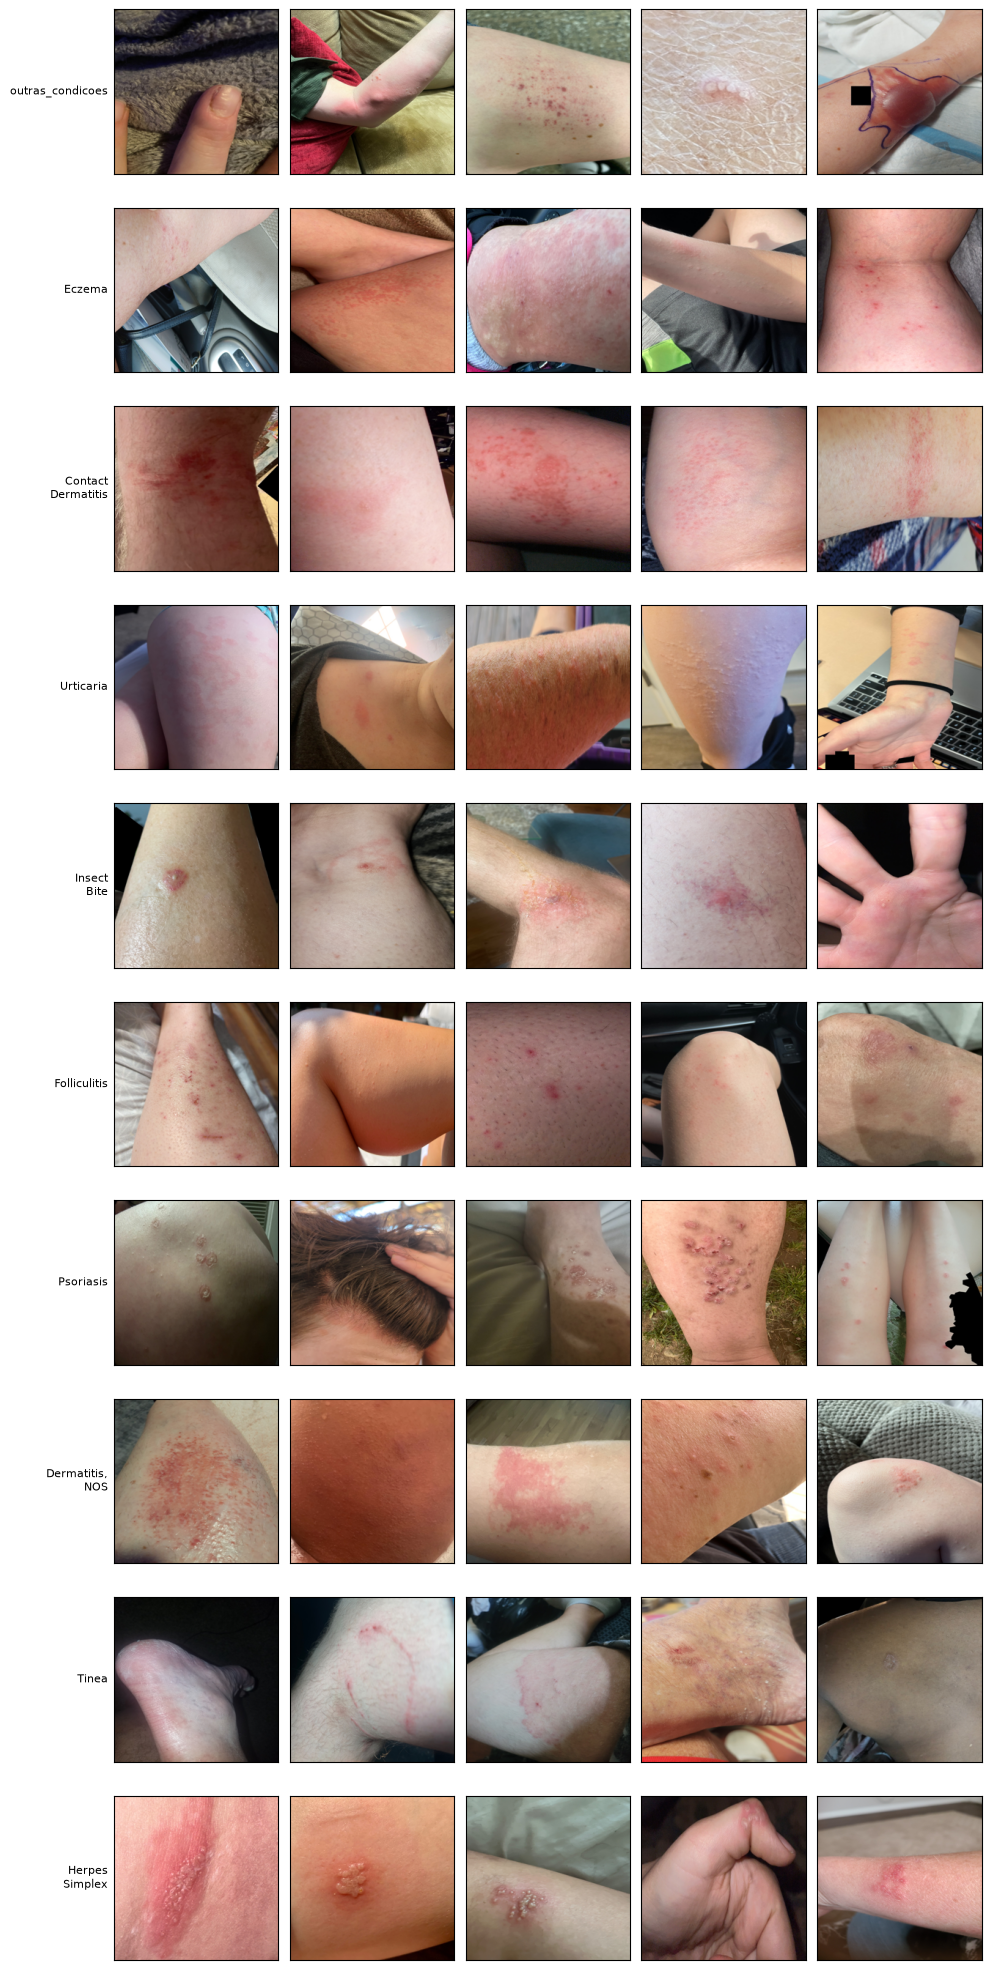

In [20]:
meta = pd.read_csv(SCIN_DIR / "meta.csv", dtype={"case_id": str, "image_id": str}, low_memory=False)
evitar = ["body_parts_genitalia_or_groin", "body_parts_buttocks", "body_parts_torso_front", "body_parts_torso_back"]
sensivel = set(scin_bruto.loc[(scin_bruto[evitar] == "YES").any(axis=1), "case_id"])
adultos = meta["age_group"].fillna("AGE_UNKNOWN") != "AGE_UNKNOWN"  # só idade declarada (18 anos ou mais)
amostra = meta[(~meta["case_id"].isin(sensivel)) & (meta["shot_type"] == "CLOSE_UP") & adultos]
classes = meta.drop_duplicates("case_id")["classe"].value_counts().index[:10]
N = 5
fig, axes = plt.subplots(len(classes), N, figsize=(2 * N, 2 * len(classes)))
for row, c in zip(axes, classes):
    imgs = amostra[amostra["classe"] == c].drop_duplicates("case_id").sample(N, random_state=42)
    for ax, (_, r) in zip(row, imgs.iterrows()):
        ax.imshow(Image.open(SCIN_DIR / r["image_path"]).convert("RGB").resize((224, 224)))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    row[0].set_ylabel(c.replace(" ", "\n"), fontsize=8, rotation=0, ha="right", va="center")
plt.tight_layout(); plt.show()

## Etapa 3: treino, validação e teste

Divisão 70/15/15 por `case_id` (as fotos de um caso são da mesma lesão), estratificada pela classe e com semente fixa. O resultado fica versionado em `splits/scin_v1.csv`. O código confere que nenhum caso ou imagem repetida aparece em dois conjuntos. O teste é separado aqui, antes de qualquer decisão de modelagem, e só entra na avaliação final.

In [21]:
N_FOLDS = 20    # 3 dobras (15%) para o teste, 3 para a validação e 14 (70%) para o treino


def make_splits(meta: pd.DataFrame) -> pd.DataFrame:
    # grupos raros entram como estrato próprio, para não caírem todos num conjunto só
    strata = meta["classe"].where(meta["grupo"] == "erupcao_alergia", meta["grupo"])
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
    split = pd.Series("train", index=meta.index)
    for fold, (_, idx) in enumerate(folds.split(meta, strata, groups=meta["case_id"])):
        if fold < 3:
            split.iloc[idx] = "test"
        elif fold < 6:
            split.iloc[idx] = "val"
    return meta.assign(split=split)


def verify(data: pd.DataFrame, images_dir: Path) -> None:
    """Interrompe com erro se algum caso ou imagem repetida estiver em mais de um conjunto."""
    assert data["image_id"].is_unique, "image_id repetido"
    per_case = data.groupby("case_id")["split"].nunique()
    assert (per_case == 1).all(), f"{(per_case > 1).sum()} casos em mais de um conjunto"
    per_md5 = data.groupby("md5")["split"].nunique()
    assert (per_md5 == 1).all(), f"{(per_md5 > 1).sum()} arquivos idênticos em mais de um conjunto"
    near = near_duplicates(data.reset_index(drop=True), images_dir)
    assert not near, f"{len(near)} quase-duplicatas restantes (r >= {NEAR_DUP_CORR})"
    print(f"Verificado: {data['case_id'].nunique()} casos em um único conjunto; sem imagens repetidas entre conjuntos")

In [22]:
scin_split = make_splits(read_ids(SCIN_DIR / "meta.csv"))
verify(scin_split, SCIN_DIR / "images")
SPLITS.mkdir(exist_ok=True)
scin_split[["image_id", "case_id", "classe", "grupo", "split"]].sort_values("image_id").to_csv(SCIN_SPLITS, index=False)
por_caso = scin_split.drop_duplicates("case_id")
print(scin_split["split"].value_counts(normalize=True).round(3).to_dict(), "(imagens)")
display(pd.crosstab(por_caso["grupo"], por_caso["split"], margins=True))
pd.crosstab(por_caso["classe"], por_caso["split"], margins=True)

C:\Users\felip\AppData\Roaming\Python\Python314\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=20.
  warnings.warn(


Verificado: 2581 casos em um único conjunto; sem imagens repetidas entre conjuntos
{'train': 0.7, 'val': 0.15, 'test': 0.15} (imagens)


split,test,train,val,All
grupo,,,,
erupcao_alergia,380,1770,380,2530
ferida,4,21,5,30
pinta,2,13,2,17
queimadura,1,3,0,4
All,387,1807,387,2581


split,test,train,val,All
classe,,,,
Acne,8,35,7,50
Contact Dermatitis,66,309,67,442
"Dermatitis, NOS",7,48,10,65
Drug Rash,6,30,6,42
Eczema,75,344,76,495
Folliculitis,17,79,18,114
Herpes Simplex,9,41,8,58
Herpes Zoster,6,33,6,45
Insect Bite,24,116,24,164


## PAD-UFES-20: fotos de celular de lesões de pele

O SCIN quase não tem pintas (17 casos depois da limpeza), e as bases do modelo de pintas são dermatoscópicas. Para ter pintas em foto de celular, baixamos o **PAD-UFES-20** (Mendeley Data, licença CC BY): 2.298 fotos de 1.373 pacientes, de lesões com diagnóstico ACK, BCC, MEL, NEV, SCC ou SEK. A divisão é por paciente. Se a base já estiver preparada, as células abaixo não baixam nada.

In [23]:
PAD_API = "https://data.mendeley.com/public-api/datasets/zr7vgbcyr2"


def baixar_pad():
    """Baixa o PAD-UFES-20 e confere o SHA-256 de cada arquivo."""
    def get(path):
        return json.load(urllib.request.urlopen(urllib.request.Request(PAD_API + path, headers={"User-Agent": "research-download"}), timeout=60))

    PAD_RAW_DIR.mkdir(parents=True, exist_ok=True)
    files = get("/files?folder_id=root&version=1")
    for folder in get("/folders/1"):
        files += get(f"/files?folder_id={folder['id']}&version=1")
    for f in files:
        info, dst = f["content_details"], PAD_RAW_DIR / f["filename"]
        if not (dst.exists() and dst.stat().st_size == info["size"]):
            print("Baixando", f["filename"], flush=True)
            with urllib.request.urlopen(urllib.request.Request(info["download_url"], headers={"User-Agent": "research-download"}), timeout=120) as r, open(dst, "wb") as out:
                while chunk := r.read(1 << 20):
                    out.write(chunk)
        h = hashlib.sha256()
        with open(dst, "rb") as source:
            while chunk := source.read(1 << 20):
                h.update(chunk)
        assert h.hexdigest() == info["sha256_hash"], f"{f['filename']} corrompido"

In [24]:
def extrair_pad(raw: Path, out: Path) -> pd.DataFrame:
    images_dir = out / "images"
    images_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for part in sorted(raw.glob("imgs_part_*.zip")):
        with zipfile.ZipFile(part) as z:
            for name in z.namelist():
                if not name.lower().endswith(".png"):
                    continue
                data = z.read(name)
                img = Image.open(io.BytesIO(data)).convert("RGB")
                image_id = Path(name).stem  # só o nome do arquivo, nunca o caminho dentro do zip
                img.save(images_dir / f"{image_id}.jpg", "JPEG", quality=95)
                rows.append({"image_id": image_id, "md5": hashlib.md5(data).hexdigest(), "phash": phash_hex(img),
                             "phash_espelho": phash_hex(ImageOps.mirror(img))})
    return pd.DataFrame(rows)


def duplicates_of_scin(images: pd.DataFrame, images_dir: Path) -> set:
    scin = read_ids(SCIN_DIR / "imagens.csv")
    scin = scin[scin["motivo"].isna()]
    target, paths = to_uint64(scin["phash"]), [SCIN_DIR / "images" / f"{i}.jpg" for i in scin["image_id"]]
    drop = set(images.index[images["md5"].isin(set(scin["md5"]))])
    h, flip = to_uint64(images["phash"]), to_uint64(images["phash_espelho"])
    for k, (idx, image_id) in enumerate(zip(images.index, images["image_id"])):
        direct, mirrored = np.bitwise_count(target ^ h[k]), np.bitwise_count(target ^ flip[k])
        for j in np.where(np.minimum(direct, mirrored) <= NEAR_DUP_MAX)[0]:
            if idx not in drop and confirmed(images_dir / f"{image_id}.jpg", paths[j], bool(mirrored[j] < direct[j])):
                drop.add(idx)
    return drop


def preparar_pad(raw=PAD_RAW_DIR, out=PAD_DIR):
    """Extrai as imagens, remove duplicatas e separa por paciente."""
    images = extrair_pad(raw, out)
    images = images.drop_duplicates("md5")
    meta = pd.read_csv(raw / "metadata.csv")
    meta["image_id"] = meta["img_id"].str.replace(".png", "", regex=False)
    table = images.merge(meta[["image_id", "patient_id", "lesion_id", "diagnostic", "region", "fitspatrick", "age", "biopsed"]],
                         on="image_id", validate="1:1")
    images_dir = out / "images"
    other_lesions = cross_duplicates(table, images_dir, SCIN_DIR)
    scin = duplicates_of_scin(table, images_dir)
    keep = ~table.index.isin(other_lesions | scin)
    table = table[keep].reset_index(drop=True)
    table["image_path"] = "images/" + table["image_id"] + ".jpg"

    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
    split = pd.Series("train", index=table.index)
    for fold, (_, idx) in enumerate(folds.split(table, table["diagnostic"], groups=table["patient_id"])):
        if fold < 3:
            split.iloc[idx] = "test"
        elif fold < 6:
            split.iloc[idx] = "val"
    table["split"] = split
    per_patient = table.groupby("patient_id")["split"].nunique()
    assert (per_patient == 1).all(), "paciente em mais de um conjunto"

    PAD_SPLITS.parent.mkdir(exist_ok=True)
    table[["image_id", "patient_id", "diagnostic", "split"]].sort_values("image_id").to_csv(PAD_SPLITS, index=False)
    table.drop(columns="split").to_csv(out / "meta.csv", index=False)  # o split fica só em splits/pad_v1.csv
    summary = {"imagens": len(table), "pacientes": int(table["patient_id"].nunique()),
               "duplicatas_com_pintas": len(other_lesions), "duplicatas_com_scin": len(scin)}
    (out / "preparo.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print(summary)
    print(pd.crosstab(table["diagnostic"], table["split"], margins=True).to_string())

In [25]:
if not (PAD_DIR / "meta.csv").exists():
    baixar_pad()
    preparar_pad()
print(json.loads((PAD_DIR / "preparo.json").read_text()))
pd.crosstab(pd.read_csv(PAD_SPLITS)["diagnostic"], pd.read_csv(PAD_SPLITS)["split"], margins=True)

{'imagens': 2283, 'pacientes': 1373, 'duplicatas_com_pintas': 0, 'duplicatas_com_scin': 0}


split,test,train,val,All
diagnostic,,,,
ACK,108,507,109,724
BCC,126,587,126,839
MEL,8,38,6,52
NEV,38,168,38,244
SCC,30,132,28,190
SEK,34,164,36,234
All,344,1596,343,2283


## Etapa 4: arquitetura e treino

```
imagem -> detector de tipo de foto -+- dermatoscopia -> modelo de pintas
                                    |
                                    +- foto de celular -> roteador -+- pinta -> modelo de pintas + orientação de avaliação médica
                                                                    +- erupção/alergia -> especialista (17 classes)
                                                                    +- baixa confiança -> "não foi possível identificar"
```

**Por que dois passos.** A proposta inicial era um único roteador juntando as bases de pintas e o SCIN. Mas as bases de pintas são dermatoscópicas e o SCIN é de celular, e o roteador aprenderia o tipo de foto, não o tipo de lesão. Assim, primeiro um detector separa dermatoscopia de celular, e o roteador compara só fotos de celular (PAD-UFES-20 × SCIN).

**Pinta em foto de celular também passa pelo modelo de pintas**, que foi adaptado para isso e sugere as classes mais prováveis. A urgência, porém, nunca cai para "cuidados em casa": foto de celular não permite descartar um câncer (o modelo ainda perde 3,4% dos malignos no teste de celular), então a saída é sempre uma orientação de avaliação médica; a suspeita só muda o texto.

**CNN como roteador, e não regras sobre a imagem**: regras manuais não separam esses grupos pela aparência. As regras entram depois da classificação, para definir a urgência (Etapa 5).

**Queimaduras e feridas ficam desativadas.** Só há 4 casos de queimadura e 30 de ferida depois da limpeza, o que não basta para treinar nem para avaliar. Os grupos estão previstos em `orientacoes.yaml`, com `ativo: false`, à espera de bases específicas.

**Rótulo único × rótulos suaves.** O especialista é treinado das duas formas, e a validação decide pelo F1 macro.

In [26]:
TRIAGEM_IMG = 224
TRIAGEM_BATCH = 32
TRIAGEM_CACHE_LADO = 256
TRIAGEM_HEAD_EPOCHS = 2
TRIAGEM_EPOCHS = 12
TRIAGEM_PATIENCE = 4
TRIAGEM_LR = 3e-4
TRIAGEM_WD = 0.02
N_DERMOSCOPY = 4000          # imagens dermatoscópicas no treino do detector de modalidade
ABSTAIN_PCT = {"roteador": 5, "especialista_erupcao": 10}  # % da validação abaixo do limiar de confiança
ROUTER_CLASSES = ["erupcao_alergia", "pinta"]
MODALITY_CLASSES = ["celular", "dermatoscopia"]
TRIAGEM_CACHE = DEFAULT_DIR.parent / "triagem_cache_256"

### Dados de cada rede

As imagens são reduzidas a lado menor de 256 px, sem mexer nas cores. Aqui não usamos Shades of Gray: a cor ajuda a sugerir a condição, e em foto de celular não há dermatoscópio para compensar. Os casos de pinta do SCIN ficam **fora do treino do roteador**, como teste externo.

In [27]:
def read_scin() -> pd.DataFrame:
    """Imagens do SCIN limpas, com o split e os rótulos suaves."""
    meta = pd.read_csv(SCIN_DIR / "meta.csv", dtype={"case_id": str, "image_id": str}, low_memory=False)
    splits = pd.read_csv(SCIN_SPLITS, dtype={"case_id": str, "image_id": str})[["image_id", "split"]]
    df = meta.merge(splits, on="image_id", validate="1:1")
    df["path"] = df["image_path"].map(lambda p: str(SCIN_DIR / p))
    return df


def read_pad() -> pd.DataFrame:
    df = pd.read_csv(PAD_DIR / "meta.csv", dtype={"patient_id": str, "lesion_id": str, "image_id": str})
    splits = pd.read_csv(PAD_SPLITS, dtype={"image_id": str})[["image_id", "split"]]
    df = df.merge(splits, on="image_id", validate="1:1")
    df["path"] = df["image_path"].map(lambda p: str(PAD_DIR / p))
    return df


def read_dermoscopy() -> pd.DataFrame:
    df = load_labels()
    df = df[df["split"].isin(["train", "val", "test"])]
    train = df[df["split"] == "train"].sample(N_DERMOSCOPY, random_state=SEED)
    df = pd.concat([train, df[df["split"] != "train"]], ignore_index=True)
    return df.assign(path=df["image_path"].astype(str))


def cached(paths) -> list:
    """Reduz as imagens a lado menor de 256 px, sem alterar as cores, uma única vez."""
    TRIAGEM_CACHE.mkdir(parents=True, exist_ok=True)

    def one(src):
        src = Path(src)
        dst = TRIAGEM_CACHE / f"{src.stem}.jpg"
        if not dst.exists():
            img = Image.open(src).convert("RGB")
            scale = TRIAGEM_CACHE_LADO / min(img.size)
            img = img.resize((round(img.width * scale), round(img.height * scale)), Image.BICUBIC)
            tmp = dst.with_suffix(".tmp")
            img.save(tmp, "JPEG", quality=95)
            os.replace(tmp, dst)
        return str(dst)

    with ThreadPoolExecutor(os.cpu_count()) as pool:
        return list(pool.map(one, paths))


def modality_data() -> pd.DataFrame:
    scin, pad, derm = read_scin(), read_pad(), read_dermoscopy()
    rows = [scin.assign(modalidade="celular", origem="SCIN"), pad.assign(modalidade="celular", origem="PAD"),
            derm.assign(modalidade="dermatoscopia", origem="ISIC")]
    data = pd.concat([r[["path", "split", "modalidade", "origem"]] for r in rows], ignore_index=True)
    return data.assign(cache=cached(data["path"]))


def router_data() -> pd.DataFrame:
    """Fotos de celular: PAD-UFES (pinta) + SCIN erupção. Os casos de pinta do SCIN ficam de fora, como teste externo."""
    scin = read_scin()
    scin = scin[scin["grupo"] == "erupcao_alergia"]
    data = pd.concat([scin.assign(rota="erupcao_alergia", origem="SCIN")[["path", "split", "rota", "origem"]],
                      read_pad().assign(rota="pinta", origem="PAD")[["path", "split", "rota", "origem"]]],
                     ignore_index=True)
    return data.assign(cache=cached(data["path"]))


def specialist_data():
    scin = read_scin()
    scin = scin[scin["grupo"] == "erupcao_alergia"].reset_index(drop=True)
    classes = sorted(c for c in scin["classe"].unique() if c != OTHER) + [OTHER]
    index = {c: i for i, c in enumerate(classes)}

    def soft(text):
        t = np.zeros(len(classes), "float32")
        for condition, weight in json.loads(text).items():
            t[index.get(condition, index[OTHER])] += weight
        return t / t.sum()

    soft_targets = np.stack(scin["rotulos_suaves"].map(soft).values)
    hard = scin["classe"].map(index).values
    return scin.assign(cache=cached(scin["path"])), classes, hard, soft_targets

### Rede e treino

A mesma receita do modelo de pintas (EfficientNetV2-B0, 224 px, transfer learning em duas fases, AdamW com decaimento cosseno, BatchNormalization congeladas). Desbalanceamento: peso pela raiz do inverso da frequência. Data augmentation com variação de cor moderada, porque a cor é informação diagnóstica.

In [28]:
def aumentar_foto(img):
    """Recortes, espelhamentos e rotações; variação de cor moderada, porque a cor ajuda a sugerir a condição."""
    begin, crop, _ = tf.image.sample_distorted_bounding_box(
        tf.shape(img), bounding_boxes=tf.zeros([1, 0, 4]), min_object_covered=0.0,
        aspect_ratio_range=(3 / 4, 4 / 3), area_range=(0.5, 1.0), max_attempts=10,
        use_image_if_no_bounding_boxes=True)
    img = tf.image.resize(tf.slice(img, begin, crop), (TRIAGEM_IMG, TRIAGEM_IMG))
    img = tf.image.random_flip_left_right(img)
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x = tf.image.random_brightness(img / 255.0, 0.1)
    x = tf.image.random_contrast(x, 0.9, 1.1)
    x = tf.image.random_saturation(x, 0.9, 1.1)
    return tf.clip_by_value(tf.image.random_hue(x, 0.01), 0.0, 1.0) * 255.0


def ds_triagem(paths, targets=None, weights=None, training=False):
    tensors = {"path": list(paths)}
    if targets is not None:
        tensors["y"] = np.asarray(targets, "float32")
    if weights is not None:
        tensors["w"] = np.asarray(weights, "float32")
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)

    def load(item):
        img = decode(item["path"])
        img = aumentar_foto(img) if training else center_crop(img, TRIAGEM_IMG)
        if "w" in item:
            return img, item["y"], item["w"]
        return (img, item["y"]) if "y" in item else img

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(TRIAGEM_BATCH, drop_remainder=training).prefetch(tf.data.AUTOTUNE)


def montar_rede(n_classes):
    base = applications.EfficientNetV2B0(include_top=False, weights="imagenet",
                                         input_shape=(TRIAGEM_IMG, TRIAGEM_IMG, 3), pooling="avg")
    image = keras.Input((TRIAGEM_IMG, TRIAGEM_IMG, 3), name="image")
    logits = layers.Dense(n_classes, name="logits")(layers.Dropout(0.3)(base(image)))
    return keras.Model(image, logits), base


class MetricasTriagem(callbacks.Callback):
    """Acurácia balanceada na validação, que escolhe o melhor checkpoint."""

    def __init__(self, ds, y):
        super().__init__()
        self.ds, self.y = ds, y

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.ds, verbose=0).argmax(1)
        logs["val_bal_acc"] = balanced_accuracy_score(self.y, pred)
        logs["val_f1_macro"] = f1_score(self.y, pred, average="macro")
        print(f"  época {epoch + 1}: val_bal_acc={logs['val_bal_acc']:.4f} val_f1_macro={logs['val_f1_macro']:.4f}", flush=True)


def pesos_classes(y, n_classes):
    """Peso pela raiz do inverso da frequência: compensa o desbalanceamento sem distorcer demais."""
    counts = np.bincount(y, minlength=n_classes).astype(float)
    w = np.sqrt(counts.sum() / np.maximum(counts, 1))
    return w / w[y].mean()


def treinar_rede(name, data, classes, targets, y=None, fine_tune=True):
    """Treina em duas fases. `targets`: matriz N x classes com a distribuição-alvo de cada imagem;
    `y`: rótulo único usado nos pesos e na validação (por padrão, o maior valor de `targets`)."""
    out = WORK_DIR / name
    out.mkdir(parents=True, exist_ok=True)
    y = targets.argmax(1) if y is None else y
    tr, va = (data["split"] == "train").values, (data["split"] == "val").values
    weights = pesos_classes(y[tr], len(classes))[y[tr]]
    train_ds = ds_triagem(data["cache"][tr], targets[tr], weights, training=True)
    val_ds = ds_triagem(data["cache"][va])
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    model, base = montar_rede(len(classes))

    head = out / "fase1.weights.h5"
    if head.exists():
        model.load_weights(head)
    else:
        base.trainable = False
        model.compile(optimizer=optimizers.AdamW(1e-3, weight_decay=TRIAGEM_WD), loss=loss)
        model.fit(train_ds, epochs=TRIAGEM_HEAD_EPOCHS, verbose=2, callbacks=[
            callbacks.BackupAndRestore(str(out / "backup_fase1")), MetricasTriagem(val_ds, y[va])])
        model.save_weights(head)
    ckpt = out / "melhor.keras"
    if not fine_tune:
        model.save(ckpt)
        return keras.models.load_model(ckpt, compile=False)

    per_epoch = int(train_ds.cardinality())
    base.trainable = True
    for layer in base.layers:  # como no modelo de pintas: BatchNormalization em modo de inferência
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    schedule = optimizers.schedules.CosineDecay(TRIAGEM_LR / 20, decay_steps=per_epoch * (TRIAGEM_EPOCHS - 1), alpha=0.01,
                                                warmup_target=TRIAGEM_LR, warmup_steps=per_epoch)
    opt = optimizers.AdamW(schedule, weight_decay=TRIAGEM_WD)
    opt.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])
    model.compile(optimizer=opt, loss=loss)
    hist = out / "historico.csv"
    best = pd.read_csv(hist)["val_bal_acc"].max() if hist.exists() and hist.stat().st_size else None
    model.fit(train_ds, epochs=TRIAGEM_EPOCHS, verbose=2, callbacks=[
        callbacks.BackupAndRestore(str(out / "backup_fase2")),
        MetricasTriagem(val_ds, y[va]),
        callbacks.ModelCheckpoint(str(ckpt), monitor="val_bal_acc", mode="max", save_best_only=True,
                                  initial_value_threshold=best),
        callbacks.EarlyStopping(monitor="val_bal_acc", mode="max", patience=TRIAGEM_PATIENCE),
        callbacks.CSVLogger(str(hist), append=True),
    ])
    return keras.models.load_model(ckpt, compile=False)

### Calibração e publicação dos modelos

A temperatura (*temperature scaling*) e o limiar de baixa confiança são ajustados **só na validação**.

In [29]:
def fit_temperature(logits, y):
    """Temperature scaling: a temperatura que minimiza a perda na validação."""
    def nll(t):
        p = scipy_softmax(logits / t, axis=1)
        return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
    return float(minimize_scalar(nll, bounds=(0.05, 10), method="bounded").x)


def update_thresholds(name, entry):
    MODELS.mkdir(parents=True, exist_ok=True)
    current = json.loads(THRESHOLDS.read_text(encoding="utf-8")) if THRESHOLDS.exists() else {}
    current[name] = entry
    THRESHOLDS.write_text(json.dumps(current, ensure_ascii=False, indent=2), encoding="utf-8")


def finish(name, model, data, classes, y, extra=None):
    """Calibra na validação, define o limiar de baixa confiança e publica o modelo."""
    va = (data["split"] == "val").values
    logits = model.predict(ds_triagem(data["cache"][va]), verbose=0)
    temperature = fit_temperature(logits, y[va])
    conf = scipy_softmax(logits / temperature, axis=1).max(1)
    pct = ABSTAIN_PCT.get(name)
    MODELS.mkdir(parents=True, exist_ok=True)
    model.save(MODELS / f"{name}.keras")
    pred = logits.argmax(1)
    update_thresholds(name, {
        "classes": classes, "temperatura": temperature,
        "limiar_confianca": float(np.percentile(conf, pct)) if pct else 0.0,
        "val_bal_acc": float(balanced_accuracy_score(y[va], pred)),
        "val_f1_macro": float(f1_score(y[va], pred, average="macro")),
        **(extra or {}),
    })
    print(f"{name}: temperatura {temperature:.3f}, val_bal_acc {balanced_accuracy_score(y[va], pred):.4f}", flush=True)


def one_hot(y, n):
    return np.eye(n, dtype="float32")[y]


def run_modality():
    data = modality_data()
    y = data["modalidade"].map({c: i for i, c in enumerate(MODALITY_CLASSES)}).values
    model = treinar_rede("modalidade", data, MODALITY_CLASSES, one_hot(y, 2), fine_tune=False)
    finish("modalidade", model, data, MODALITY_CLASSES, y)


def run_router():
    data = router_data()
    y = data["rota"].map({c: i for i, c in enumerate(ROUTER_CLASSES)}).values
    model = treinar_rede("roteador", data, ROUTER_CLASSES, one_hot(y, 2))
    finish("roteador", model, data, ROUTER_CLASSES, y)


def run_specialist():
    """Treina com rótulo único e com rótulos suaves; a validação decide qual fica."""
    data, classes, hard, soft_targets = specialist_data()
    va = (data["split"] == "val").values
    scores, trained = {}, {}
    for mode, targets in (("unico", one_hot(hard, len(classes))), ("suave", soft_targets)):
        trained[mode] = treinar_rede(f"especialista_{mode}", data, classes, targets, hard)
        pred = trained[mode].predict(ds_triagem(data["cache"][va]), verbose=0).argmax(1)
        scores[mode] = {"val_bal_acc": float(balanced_accuracy_score(hard[va], pred)),
                        "val_f1_macro": float(f1_score(hard[va], pred, average="macro"))}
    best = max(scores, key=lambda m: scores[m]["val_f1_macro"])
    print("Comparação na validação:", scores, "-> escolhido:", best, flush=True)
    finish("especialista_erupcao", trained[best], data, classes, hard, {"rotulo": best, "comparacao": scores})


def run_lesions():
    """Publica os parâmetros de decisão do modelo de pintas, definidos no início deste notebook."""
    update_thresholds("pintas", {"classes": CLASSES, "tau": TAU, "log_prior": LOG_PRIOR.tolist(),
                                 "limiar_maligno": LIMIAR_MALIGNO})
    print(f"pintas: tau {TAU:.2f}, limiar de malignidade {LIMIAR_MALIGNO:.3f}")

### Treinando

Cada rede só é treinada se ainda não estiver em `modelos/triagem/`. Para treinar de novo, apague o `.keras` correspondente. Na CPU, são cerca de 2h30 ao todo.

In [30]:
treinos = {"modalidade": run_modality, "roteador": run_router, "especialista_erupcao": run_specialist}
for nome, rodar in treinos.items():
    if (MODELS / f"{nome}.keras").exists():
        print(f"{nome}: já treinado, pulando")
    else:
        rodar()
run_lesions()

resumo = json.loads(THRESHOLDS.read_text(encoding="utf-8"))
pd.DataFrame({k: {c: v.get(c) for c in ("temperatura", "limiar_confianca", "val_bal_acc", "val_f1_macro", "rotulo")}
              for k, v in resumo.items() if k != "pintas"}).T.round(3)

modalidade: já treinado, pulando
roteador: já treinado, pulando
especialista_erupcao: já treinado, pulando
pintas: tau 1.10, limiar de malignidade 0.287


,temperatura,limiar_confianca,val_bal_acc,val_f1_macro,rotulo
modalidade,0.632577,0.0,0.977879,0.975157,NaN
roteador,1.190937,0.855562,0.978556,0.978158,NaN
especialista_erupcao,1.419258,0.209963,0.239236,0.252713,suave


## Etapa 5: orientação de próximo passo

A orientação **nunca é gerada pelo modelo**: vem só de `config/orientacoes.yaml`, que associa cada condição a um nível de urgência (🔴 emergência, 🟠 consulta em breve, 🟢 cuidados em casa). O arquivo está marcado como **rascunho a ser revisado por um profissional de saúde**.

- **Perguntas de alerta** elevam a urgência independentemente da previsão: falta de ar ou inchaço, manchas roxas com febre, pele descolando ou lesões em mucosas, queimadura grave, febre, lesão que se espalha rápido, pus, criança ou idoso, diabetes.
- **Baixa confiança** resulta em "não foi possível identificar; procure avaliação médica". Os limiares vêm da validação.
- A função única é `triagem(imagem, respostas_alerta)`, que devolve o grupo, as 3 condições mais prováveis com probabilidades, o nível de urgência e a orientação.

In [31]:
print((REPO / "config" / "orientacoes.yaml").read_text(encoding="utf-8")[:1500], "...")

# RASCUNHO A SER REVISADO POR UM PROFISSIONAL DE SAÚDE.
# Projeto acadêmico de apoio à triagem: o resultado é uma sugestão ou orientação, nunca um diagnóstico.
# Toda orientação mostrada ao usuário vem deste arquivo, e nunca de texto gerado pelo modelo.
#
# Critério usado neste rascunho: na dúvida, o nível mais alto. O erro mais grave do sistema é
# orientar cuidados em casa para algo que precisaria de atendimento.

niveis:
  emergencia:
    ordem: 3
    rotulo: "🔴 Emergência"
    orientacao: "Procure um pronto-socorro agora ou ligue para o SAMU (192)."
  breve:
    ordem: 2
    rotulo: "🟠 Consulta em breve"
    orientacao: "Procure um médico nos próximos dias."
  casa:
    ordem: 1
    rotulo: "🟢 Cuidados em casa"
    orientacao: "Pode observar em casa. Procure atendimento se piorar, se espalhar ou se não melhorar em alguns dias."

aviso: "Esta é uma sugestão de um sistema acadêmico de apoio à triagem. Não substitui a avaliação de um profissional de saúde."

nao_identificado:
  urgenc

In [32]:
LESION_MODEL = RAIZ / "modelos" / "pintas" / "melhor.keras"
TRIAGEM_TTA = 8


def config() -> dict:
    cfg = yaml.safe_load((REPO / "config" / "orientacoes.yaml").read_text(encoding="utf-8"))
    missing = set(limiares()["especialista_erupcao"]["classes"]) - set(cfg["condicoes"])
    if missing:
        raise ValueError(f"Condições sem orientação em orientacoes.yaml: {sorted(missing)}")
    return cfg


def limiares() -> dict:
    return json.loads((MODELS / "limiares.json").read_text(encoding="utf-8"))


def modelo(nome: str):
    return keras.models.load_model(LESION_MODEL if nome == "pintas" else MODELS / f"{nome}.keras", compile=False)


def preparar(imagem, lado: int) -> np.ndarray:
    """Imagem RGB com o lado menor igual a `lado`."""
    img = Image.open(imagem) if isinstance(imagem, (str, Path)) else imagem
    img = img.convert("RGB")
    escala = lado / min(img.size)
    return np.asarray(img.resize((round(img.width * escala), round(img.height * escala)), Image.BICUBIC))


def entrada_celular(imagem) -> np.ndarray:
    return center_crop(tf.constant(preparar(imagem, 256), tf.float32), TRIAGEM_IMG).numpy()


def calibradas(nome: str, lote: np.ndarray) -> np.ndarray:
    return scipy_softmax(modelo(nome).predict(lote, verbose=0) / limiares()[nome]["temperatura"], axis=1)


def top3(probs: np.ndarray, classes: list, nomes) -> list:
    return [{"condicao": classes[i], "nome": nomes(classes[i]), "probabilidade": round(float(probs[i]), 4)}
            for i in np.argsort(probs)[::-1][:3]]


def decidir_celular(p_rota: np.ndarray, p_especialista=None, p_pinta=None) -> dict:
    """Decisão para foto de celular a partir das probabilidades calibradas de cada rede."""
    cfg, lim = config(), limiares()
    rotas = lim["roteador"]["classes"]
    if p_rota.max() < lim["roteador"]["limiar_confianca"]:
        return nao_identificado("fora_do_escopo")
    grupo = rotas[int(p_rota.argmax())]
    if grupo == "pinta":
        return decidir_pinta_celular(p_pinta)
    classes = lim["especialista_erupcao"]["classes"]
    if p_especialista is None or p_especialista.max() < lim["especialista_erupcao"]["limiar_confianca"]:
        return nao_identificado(grupo)
    regra = cfg["condicoes"][classes[int(p_especialista.argmax())]]
    return {"grupo": grupo, "condicoes": top3(p_especialista, classes, lambda c: cfg["condicoes"][c]["nome"]),
            "urgencia": regra["urgencia"], "orientacao": regra["orientacao"], "baixa_confianca": False}


def decidir_pinta_celular(p=None) -> dict:
    """Pinta em foto de celular: o modelo sugere classes e ajusta o texto, mas a urgência é fixa.

    A foto de celular não permite descartar um câncer, então a orientação nunca vira "em casa".
    """
    regra = config()["pinta_celular"]
    base = {"grupo": "pinta", "condicoes": [], "urgencia": regra["urgencia"], "orientacao": regra["orientacao"],
            "baixa_confianca": False}
    if p is None:
        return base
    lim = limiares()["pintas"]
    classes = lim["classes"]
    ajustadas = scipy_softmax(np.log(p + 1e-12) - lim["tau"] * np.array(lim["log_prior"]))
    maligno = sum(float(p[classes.index(c)]) for c in ("ak", "bcc", "mel", "scc"))
    if maligno >= lim["limiar_maligno"]:
        base["orientacao"] = regra["orientacao_suspeita"]
    return {**base, "condicoes": top3(ajustadas, classes, DX_NAMES.get), "probabilidade_maligno": round(maligno, 4)}


def decidir_dermatoscopia(p: np.ndarray) -> dict:
    """Decisão para imagem dermatoscópica a partir das probabilidades do modelo de pintas."""
    cfg, lim = config(), limiares()["pintas"]
    classes = lim["classes"]
    ajustadas = scipy_softmax(np.log(p + 1e-12) - lim["tau"] * np.array(lim["log_prior"]))
    maligno = sum(float(p[classes.index(c)]) for c in ("ak", "bcc", "mel", "scc"))
    regra = cfg["pinta_dermatoscopia"]["suspeita" if maligno >= lim["limiar_maligno"] else "baixa_suspeita"]
    return {"grupo": "pinta", "condicoes": top3(ajustadas, classes, DX_NAMES.get), **regra, "baixa_confianca": False,
            "probabilidade_maligno": round(maligno, 4)}


def nao_identificado(grupo: str) -> dict:
    return {"grupo": grupo, "condicoes": [], **config()["nao_identificado"], "baixa_confianca": True}


def aplicar_alertas(resultado: dict, respostas: dict) -> dict:
    """Eleva a urgência conforme as respostas: vale sempre o nível mais alto."""
    cfg = config()
    niveis = cfg["niveis"]
    acionados = [a for a in cfg["alertas"] if respostas.get(a["id"])]
    urgencia = resultado["urgencia"]
    for alerta in acionados:
        if niveis[alerta["eleva_para"]]["ordem"] > niveis[urgencia]["ordem"]:
            urgencia = alerta["eleva_para"]
    if urgencia != resultado["urgencia"]:
        resultado["orientacao"] = f"{niveis[urgencia]['orientacao']} {resultado['orientacao']}"
    return {**resultado, "urgencia": urgencia, "rotulo_urgencia": niveis[urgencia]["rotulo"],
            "alertas_acionados": [a["id"] for a in acionados], "aviso": cfg["aviso"]}


def probs_pintas(imagem) -> np.ndarray:
    """Probabilidades do modelo de pintas com TTA. Sem metadados: idade, sexo e região entram como ausentes."""
    img = shades_of_gray(preparar(imagem, 288))
    x = center_crop(tf.constant(img, tf.float32), TRIAGEM_IMG)
    meta = meta_features(pd.DataFrame({"age_approx": [np.nan], "sex": [None], "site": [None]}))
    views = [tf.image.rot90(x, k % 4) if k < 4 else tf.image.flip_left_right(tf.image.rot90(x, k % 4)) for k in range(TRIAGEM_TTA)]
    lote = {"image": np.stack([v.numpy() for v in views]), "meta": np.repeat(meta, TRIAGEM_TTA, axis=0)}
    return scipy_softmax(modelo("pintas").predict(lote, verbose=0), axis=1).mean(0)


def triagem(imagem, respostas_alerta: dict | None = None) -> dict:
    """Devolve grupo, 3 condições mais prováveis, nível de urgência e orientação.

    imagem: caminho do arquivo ou PIL.Image. respostas_alerta: {id do alerta: True/False}, com os
    ids de `alertas` em config/orientacoes.yaml; pergunta sem resposta conta como "não".
    """
    respostas = respostas_alerta or {}
    x = entrada_celular(imagem)[None]
    tipos = limiares()["modalidade"]["classes"]
    modalidade = tipos[int(calibradas("modalidade", x)[0].argmax())]
    if modalidade == "dermatoscopia":
        resultado = decidir_dermatoscopia(probs_pintas(imagem))
    else:
        p_rota = calibradas("roteador", x)[0]
        p_esp = calibradas("especialista_erupcao", x)[0]
        pinta = limiares()["roteador"]["classes"][int(p_rota.argmax())] == "pinta"
        resultado = decidir_celular(p_rota, p_esp, probs_pintas(imagem) if pinta else None)
    return aplicar_alertas({"modalidade": modalidade, **resultado}, respostas)

### Exemplo

A mesma imagem sem alertas e com a resposta "há falta de ar ou inchaço". Com o alerta, a urgência sobe para emergência, independentemente do modelo.

In [33]:
meta_teste = read_scin()
meta_teste = meta_teste[(meta_teste["split"] == "test") & (meta_teste["classe"] == "Urticaria")]
exemplo_img = meta_teste["path"].iloc[0]
print(json.dumps(triagem(exemplo_img), ensure_ascii=False, indent=1))
com_alerta = triagem(exemplo_img, {"falta_ar_inchaco": True})
print("\nCom alerta:", com_alerta["rotulo_urgencia"], "|", com_alerta["orientacao"])

{
 "modalidade": "celular",
 "grupo": "erupcao_alergia",
 "condicoes": [
  {
   "condicao": "outras_condicoes",
   "nome": "Outra condição de pele",
   "probabilidade": 0.2374
  },
  {
   "condicao": "Contact Dermatitis",
   "nome": "Dermatite de contato",
   "probabilidade": 0.2105
  },
  {
   "condicao": "Urticaria",
   "nome": "Urticária",
   "probabilidade": 0.1551
  }
 ],
 "urgencia": "breve",
 "orientacao": "A imagem não se parece com as condições mais comuns que o sistema conhece. Procure avaliação médica.",
 "baixa_confianca": false,
 "rotulo_urgencia": "🟠 Consulta em breve",
 "alertas_acionados": [],
 "aviso": "Esta é uma sugestão de um sistema acadêmico de apoio à triagem. Não substitui a avaliação de um profissional de saúde."
}



Com alerta: 🔴 Emergência | Procure um pronto-socorro agora ou ligue para o SAMU (192). A imagem não se parece com as condições mais comuns que o sistema conhece. Procure avaliação médica.


In [34]:
# O mesmo modelo de pintas nas duas rotas: um melanoma em foto de celular e um em dermatoscopia
pad_teste = read_pad()
pad_teste = pad_teste[(pad_teste["split"] == "test") & (pad_teste["diagnostic"] == "MEL")]
derm_teste = load_labels().query('split == "test" and dx_ham == "mel"').sample(1, random_state=SEED)
for titulo, caminho in [("Foto de celular (PAD-UFES-20)", pad_teste["path"].iloc[0]),
                        ("Dermatoscopia (ISIC 2018)", derm_teste["image_path"].iloc[0])]:
    r = triagem(caminho)
    print(f"{titulo}: modalidade {r['modalidade']}, grupo {r['grupo']}, {r['rotulo_urgencia']}")
    print(f"  sugestões: {[(c['nome'], c['probabilidade']) for c in r['condicoes']]}")
    print(f"  probabilidade de malignidade: {r.get('probabilidade_maligno')}")
    print(f"  orientação: {r['orientacao']}\n")

Foto de celular (PAD-UFES-20): modalidade celular, grupo pinta, 🟠 Consulta em breve
  sugestões: [('Dermatofibroma', 0.4156), ('Melanoma', 0.3509), ('Lesão benigna tipo queratose', 0.1044)]
  probabilidade de malignidade: 0.7214
  orientação: A foto tem características que merecem avaliação. Agende uma consulta com dermatologista em breve, de preferência com dermatoscopia.



Dermatoscopia (ISIC 2018): modalidade dermatoscopia, grupo pinta, 🟠 Consulta em breve
  sugestões: [('Melanoma', 0.8901), ('Nevo melanocítico', 0.1094), ('Lesão benigna tipo queratose', 0.0003)]
  probabilidade de malignidade: 0.8688
  orientação: A imagem tem características que merecem avaliação. Agende uma consulta com dermatologista em breve.



## Etapa 6: avaliação no conjunto de teste

Cada imagem de teste percorre o sistema todo. Os modelos, a calibração e os limiares já estão fixos: esta é a avaliação final. As figuras ficam em `relatorios/figuras/`.

Na medida de erro grave, a **urgência de referência** vem da condição rotulada e de `orientacoes.yaml` (nas pintas, maligna = consulta em breve; benigna = cuidados em casa; feridas e queimaduras = consulta em breve). As perguntas de alerta ficam sem resposta, o pior caso.

In [35]:
MALIGNANT_SCIN = ("melanoma", "basal cell", "squamous cell", "actinic keratosis", "keratoacanthoma")
MALIGNANT_PAD = {"BCC", "MEL", "SCC", "ACK"}


def logits_of(name, paths):
    return modelo(name).predict(ds_triagem(paths), verbose=0)


def ece(probs, y, bins=15):
    """Erro de calibração esperado da classe prevista; devolve também os pontos do diagrama."""
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    total, points = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            acc, c = (pred[mask] == y[mask]).mean(), conf[mask].mean()
            total += mask.mean() * abs(acc - c)
            points.append((float(c), float(acc), int(mask.sum())))
    return float(total), points


def calibration(name, logits, y):
    t = limiares()[name]["temperatura"]
    before, _ = ece(scipy_softmax(logits, axis=1), y)
    after, points = ece(scipy_softmax(logits / t, axis=1), y)
    return {"temperatura": t, "ece_antes": before, "ece_depois": after}, points


def plot_confusion(y, pred, labels, title, name, size=(7, 6)):
    cm = confusion_matrix(y, pred, labels=range(len(labels)), normalize="true")
    fig, ax = plt.subplots(figsize=size)
    sns.heatmap(cm, annot=len(labels) <= 8, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=len(labels) > 8,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set(xlabel="Previsto", ylabel="Real", title=title)
    plt.tight_layout()
    fig.savefig(FIGURAS / name, dpi=140)
    plt.show()


def evaluate_modality():
    data = modality_data()
    test = data[data["split"] == "test"].reset_index(drop=True)
    y = test["modalidade"].map({c: i for i, c in enumerate(MODALITY_CLASSES)}).values
    pred = logits_of("modalidade", test["cache"]).argmax(1)
    plot_confusion(y, pred, MODALITY_CLASSES, "Modalidade: fração de cada classe real", "modalidade_confusao.png", (4.5, 3.8))
    return {"n": len(test), "acuracia_balanceada": balanced_accuracy_score(y, pred),
            "acuracia_por_origem": {o: float((pred[test["origem"] == o] == y[test["origem"] == o]).mean())
                                    for o in test["origem"].unique()}}


def evaluate_router():
    data = router_data()
    test = data[data["split"] == "test"].reset_index(drop=True)
    y = test["rota"].map({c: i for i, c in enumerate(ROUTER_CLASSES)}).values
    logits = logits_of("roteador", test["cache"])
    pred = logits.argmax(1)
    plot_confusion(y, pred, ROUTER_CLASSES, "Roteador: fração de cada classe real", "roteador_confusao.png", (4.5, 3.8))
    calib, points = calibration("roteador", logits, y)
    lim = limiares()["roteador"]["limiar_confianca"]
    conf = scipy_softmax(logits / calib["temperatura"], axis=1).max(1)

    # teste externo: pintas do SCIN, de outra origem, que o roteador nunca viu no treino
    scin = read_scin()
    moles = scin[scin["grupo"] == "pinta"]
    ext = scipy_softmax(logits_of("roteador", cached(moles["path"])) / calib["temperatura"], axis=1)
    pinta = ROUTER_CLASSES.index("pinta")
    return {
        "n": len(test), "acuracia_balanceada": balanced_accuracy_score(y, pred),
        "f1_por_classe": dict(zip(ROUTER_CLASSES, f1_score(y, pred, average=None).tolist())),
        "fora_do_escopo_pct": float((conf < lim).mean()),
        "calibracao": calib,
        "pintas_scin_externo": {"imagens": len(moles), "casos": int(moles["case_id"].nunique()),
                                "recall_pinta": float((ext.argmax(1) == pinta).mean())},
    }, points


def evaluate_specialist():
    data, classes, hard, _ = specialist_data()
    te = (data["split"] == "test").values
    test, y = data[te].reset_index(drop=True), hard[te]
    logits = logits_of("especialista_erupcao", test["cache"])
    calib, points = calibration("especialista_erupcao", logits, y)
    probs = scipy_softmax(logits / calib["temperatura"], axis=1)
    pred = probs.argmax(1)
    plot_confusion(y, pred, classes, "Especialista: fração de cada classe real", "especialista_confusao.png", (9, 8))
    present = sorted(set(y))
    auc = roc_auc_score(np.eye(len(classes))[y][:, present], probs[:, present], average="macro")

    # um caso tem até 3 fotos: média das probabilidades por caso
    by_case = pd.DataFrame(probs).groupby(test["case_id"].values).mean()
    case_y = pd.Series(y).groupby(test["case_id"].values).first().reindex(by_case.index).values
    case_pred = by_case.values.argmax(1)
    sens = recall_score(y, pred, labels=range(len(classes)), average=None, zero_division=0)
    top3 = np.argsort(probs, axis=1)[:, -3:]
    lim = limiares()["especialista_erupcao"]["limiar_confianca"]
    result = {
        "n_imagens": len(test), "n_casos": int(test["case_id"].nunique()), "n_classes": len(classes),
        "rotulo_usado": limiares()["especialista_erupcao"].get("rotulo"),
        "comparacao_val": limiares()["especialista_erupcao"].get("comparacao"),
        "acuracia": accuracy_score(y, pred), "acuracia_top3": float(np.mean([y[i] in top3[i] for i in range(len(y))])),
        "acuracia_balanceada": balanced_accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0), "auroc_macro": float(auc),
        "acuracia_por_caso": accuracy_score(case_y, case_pred),
        "sem_identificar_pct": float((probs.max(1) < lim).mean()),
        "sensibilidade_por_classe": {c: float(s) for c, s in zip(classes, sens)},
        "calibracao": calib,
    }
    return result, points, test, probs, y


def reference_urgency(row, cfg):
    if row["origem"] == "SCIN":
        if row["grupo"] == "erupcao_alergia":
            return cfg["condicoes"][row["classe"]]["urgencia"]
        if row["grupo"] == "pinta":
            return "breve" if any(t in row["condicao"].lower() for t in MALIGNANT_SCIN) else "casa"
        return "breve"  # ferida ou queimadura
    return "breve" if row["maligna"] else "casa"


def evaluate_system():
    """Cada imagem de teste percorre o sistema todo, sem respostas de alerta (o pior caso)."""
    cfg = config()
    scin = read_scin()
    scin = scin[scin["split"] == "test"].assign(origem="SCIN")
    pad = read_pad()
    pad = pad[pad["split"] == "test"].assign(origem="PAD", maligna=lambda d: d["diagnostic"].isin(MALIGNANT_PAD))
    derm = load_labels()
    derm = derm[derm["split"] == "test"].assign(origem="ISIC", maligna=lambda d: d["malignant"] == 1,
                                                 path=lambda d: d["image_path"].astype(str), file_id=lambda d: d["file_id"].astype(str))
    data = pd.concat([scin, pad, derm], ignore_index=True)
    data["cache"] = cached(data["path"])
    data["referencia"] = data.apply(reference_urgency, axis=1, cfg=cfg)

    temp = {n: limiares()[n]["temperatura"] for n in ("modalidade", "roteador", "especialista_erupcao")}
    modal = logits_of("modalidade", data["cache"]).argmax(1)
    p_rota = scipy_softmax(logits_of("roteador", data["cache"]) / temp["roteador"], axis=1)
    p_esp = scipy_softmax(logits_of("especialista_erupcao", data["cache"]) / temp["especialista_erupcao"], axis=1)
    stored = np.load(RAIZ / "modelos" / "pintas" / "probs_isic2018.npz")
    lesion = dict(zip(stored["ids_test"].astype(str), stored["test"]))

    decisions = []
    for i, row in enumerate(data.itertuples()):
        # foto de celular confundida com dermatoscopia segue pela rota de celular; o total sai no relatório
        if MODALITY_CLASSES[modal[i]] == "dermatoscopia" and row.origem == "ISIC":
            decisions.append(decidir_dermatoscopia(lesion[row.file_id]))
        else:
            decisions.append(decidir_celular(p_rota[i], p_esp[i]))
    data["urgencia"] = [d["urgencia"] for d in decisions]
    data["baixa_confianca"] = [d["baixa_confianca"] for d in decisions]
    data["grave"] = (data["urgencia"] == "casa") & (data["referencia"] != "casa")

    def summary(df):
        need = df["referencia"] != "casa"
        return {"n": len(df), "precisa_atendimento": int(need.sum()),
                "taxa_erro_grave": float(df.loc[need, "grave"].mean()) if need.any() else None,
                "erros_graves": int(df["grave"].sum()),
                "sem_identificar_pct": float(df["baixa_confianca"].mean()),
                "excesso_cautela": float((df.loc[~need, "urgencia"] != "casa").mean()) if (~need).any() else None}

    tones = data[data["origem"] == "SCIN"]
    wrong = (data["origem"] != "ISIC") & (modal == MODALITY_CLASSES.index("dermatoscopia"))
    return {"geral": summary(data), "por_origem": {o: summary(g) for o, g in data.groupby("origem")},
            "celular_confundida_com_dermatoscopia": int(wrong.sum())}, tones


def tone_groups(meta, test, probs, y, tones):
    """Desempenho do especialista e erros graves por tipo de pele. Grupos pequenos têm pouca evidência."""
    extra = test.assign(acerto=probs.argmax(1) == y)
    top3 = np.argsort(probs, axis=1)[:, -3:]
    extra["acerto_top3"] = [y[i] in top3[i] for i in range(len(y))]
    monk = pd.cut(extra["monk_skin_tone_label_us"], [0, 2, 4, 6, 10], labels=["1-2", "3-4", "5-6", "7-10"])
    fitz = extra["fitzpatrick_skin_type"].map({"FST1": "I-II", "FST2": "I-II", "FST3": "III-IV", "FST4": "III-IV",
                                               "FST5": "V-VI", "FST6": "V-VI"})
    def table(groups):
        rows = {}
        for g, df in extra.groupby(groups, observed=True):
            idx = df.index
            rows[str(g)] = {"imagens": len(df), "casos": int(df["case_id"].nunique()),
                            "acuracia": float(df["acerto"].mean()), "acuracia_top3": float(df["acerto_top3"].mean()),
                            "acuracia_balanceada": balanced_accuracy_score(y[idx], probs[idx].argmax(1))}
        return rows

    grave = tones.assign(monk=pd.cut(tones["monk_skin_tone_label_us"], [0, 2, 4, 6, 10], labels=["1-2", "3-4", "5-6", "7-10"]))
    need = grave[grave["referencia"] != "casa"]
    return {"monk": table(monk), "fitzpatrick": table(fitz),
            "erro_grave_por_monk": {str(k): {"precisa_atendimento": len(v), "taxa": float(v["grave"].mean())}
                                    for k, v in need.groupby("monk", observed=True)}}


def plot_reliability(curves):
    fig, axes = plt.subplots(1, len(curves), figsize=(4 * len(curves), 3.6))
    for ax, (name, points) in zip(np.atleast_1d(axes), curves.items()):
        conf, acc, _ = zip(*points)
        ax.plot([0, 1], [0, 1], color="#999", linestyle="--", linewidth=1)
        ax.plot(conf, acc, marker="o", color=BLUE, linewidth=2, markersize=5)
        ax.set(xlabel="Confiança prevista", ylabel="Acerto observado", title=name, xlim=(0, 1), ylim=(0, 1))
        ax.grid(color="#e6e6e6")
    plt.tight_layout()
    fig.savefig(FIGURAS / "calibracao.png", dpi=140)
    plt.show()


def safe_cases() -> set:
    """Casos sem tronco nem região genital e com idade adulta declarada, os únicos usados em figuras."""
    avoid = ["body_parts_genitalia_or_groin", "body_parts_buttocks", "body_parts_torso_front", "body_parts_torso_back"]
    cols = ["case_id", "age_group"] + avoid
    df = pd.concat([pq.read_table(f, columns=cols).to_pandas() for f in glob.glob(str(SCIN_RAW_DIR / "*.parquet"))])
    ok = (df[avoid] != "YES").all(axis=1) & df["age_group"].notna() & (df["age_group"] != "AGE_UNKNOWN")
    return set(df.loc[ok, "case_id"])


def grad_cam(name, x, class_idx):
    model = modelo(name)
    base = next(layer for layer in model.layers if hasattr(layer, "layers"))
    inner = keras.Model(base.input, [base.get_layer("top_activation").output, base.output])
    dense = model.get_layer("logits")
    with tf.GradientTape() as tape:
        conv, _ = inner(x, training=False)
        tape.watch(conv)
        score = dense(tf.reduce_mean(conv, axis=[1, 2]))[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * conv, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return np.asarray(Image.fromarray((cam * 255).astype("uint8")).resize((224, 224), Image.BICUBIC)) / 255.0


def plot_grad_cam(test, probs):
    safe = test[test["case_id"].isin(safe_cases()) & (test["shot_type"] == "CLOSE_UP")].drop_duplicates("case_id")
    sample = safe.sample(min(12, len(safe)), random_state=7)
    classes = limiares()["especialista_erupcao"]["classes"]
    fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
    for ax_pair, (idx, row) in zip(axes.reshape(-1, 2), sample.iterrows()):
        img = np.asarray(Image.open(row["cache"]).convert("RGB").resize((224, 224)), "float32")
        k = int(probs[idx].argmax())
        cam = grad_cam("especialista_erupcao", img[None], k)
        ax_pair[0].imshow(img.astype("uint8"))
        ax_pair[0].set_title(f"real: {row['classe']}"[:28], fontsize=7)
        ax_pair[1].imshow(img.astype("uint8"))
        ax_pair[1].imshow(cam, cmap="jet", alpha=0.45)
        ax_pair[1].set_title(f"sugestão: {classes[k]}"[:28], fontsize=7)
        for a in ax_pair:
            a.axis("off")
    plt.tight_layout()
    fig.savefig(FIGURAS / "grad_cam_especialista.png", dpi=130)
    plt.show()

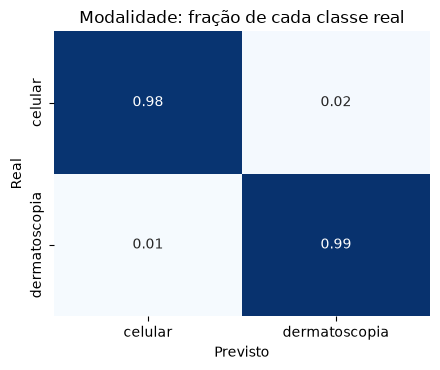

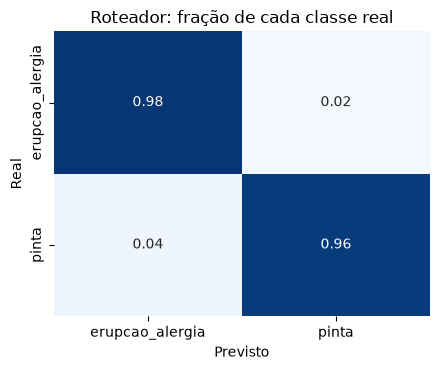

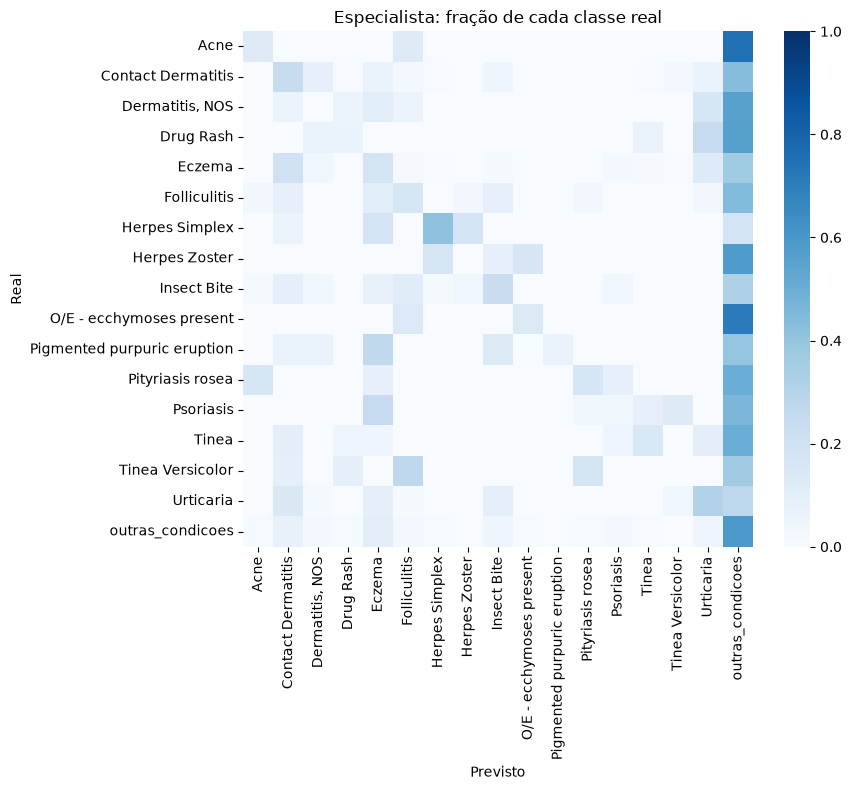

C:\Users\felip\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\felip\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\felip\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\felip\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


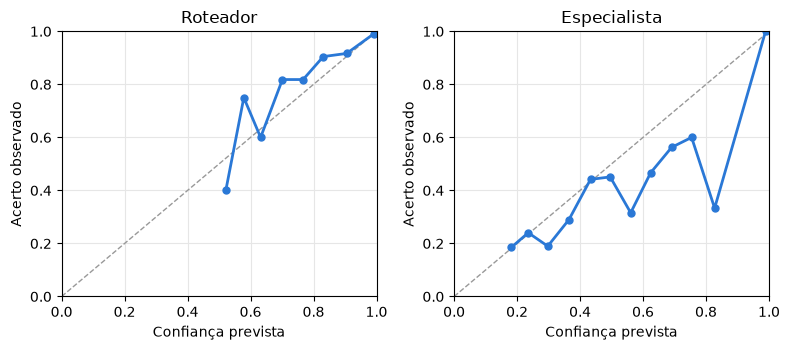

5214

In [36]:
FIGURAS.mkdir(parents=True, exist_ok=True)
metricas = {"modalidade": evaluate_modality()}
metricas["roteador"], curva_roteador = evaluate_router()
metricas["especialista"], curva_especialista, teste_esp, probs_esp, y_esp = evaluate_specialist()
metricas["sistema"], tons = evaluate_system()
metricas["tipo_de_pele"] = tone_groups(None, teste_esp, probs_esp, y_esp, tons)
plot_reliability({"Roteador": curva_roteador, "Especialista": curva_especialista})
(RELATORIOS / "metricas_triagem.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

### Detector de modalidade e roteador

In [37]:
r = metricas["roteador"]
display(pd.Series({"Modalidade: acurácia balanceada": metricas["modalidade"]["acuracia_balanceada"],
                   **{f"Modalidade: acerto em {k}": v for k, v in metricas["modalidade"]["acuracia_por_origem"].items()},
                   "Roteador: acurácia balanceada": r["acuracia_balanceada"],
                   "Roteador: F1 pinta": r["f1_por_classe"]["pinta"],
                   "Roteador: F1 erupção/alergia": r["f1_por_classe"]["erupcao_alergia"],
                   "Roteador: fora do escopo": r["fora_do_escopo_pct"],
                   "Pintas do SCIN (teste externo): reconhecidas": r["pintas_scin_externo"]["recall_pinta"]}, name="valor").round(3).to_frame())

,valor
Modalidade: acurácia balanceada,0.986
Modalidade: acerto em SCIN,0.993
Modalidade: acerto em PAD,0.953
Modalidade: acerto em ISIC,0.991
Roteador: acurácia balanceada,0.968
Roteador: F1 pinta,0.955
Roteador: F1 erupção/alergia,0.981
Roteador: fora do escopo,0.059
Pintas do SCIN (teste externo): reconhecidas,0.057


**Resultado.** O detector de tipo de foto funciona bem (98,6% de acurácia balanceada).

O roteador acerta 96,8% no teste, **mas esse número engana**. Ele reconheceu só **2 das 35 imagens (5,7%)** de pintas do próprio SCIN, que nunca viu no treino. Ou seja, aprendeu em boa parte a diferença entre **as bases** (fotos de clínica do PAD-UFES e fotos caseiras do SCIN) e não entre pinta e erupção. É o risco previsto na arquitetura, agora medido. **Na prática, uma pinta fotografada em casa tende a ser tratada como erupção.**

### Especialista em erupções e alergias

In [38]:
e = metricas["especialista"]
display(pd.Series({k: e[k] for k in ("n_imagens", "n_casos", "acuracia", "acuracia_top3", "acuracia_por_caso", "acuracia_balanceada", "f1_macro", "auroc_macro", "sem_identificar_pct")}, name="valor").round(3).to_frame())
display(pd.DataFrame(e["comparacao_val"]).T.round(3))
pd.Series(e["sensibilidade_por_classe"], name="sensibilidade").sort_values(ascending=False).round(2).to_frame()

,valor
n_imagens,802.000
n_casos,380.000
acuracia,0.283
acuracia_top3,0.692
acuracia_por_caso,0.334
acuracia_balanceada,0.170
f1_macro,0.182
auroc_macro,0.806
sem_identificar_pct,0.106


,val_bal_acc,val_f1_macro
unico,0.263,0.231
suave,0.239,0.253


,sensibilidade
outras_condicoes,0.59
Herpes Simplex,0.41
Urticaria,0.31
Contact Dermatitis,0.24
Insect Bite,0.23
Eczema,0.18
Folliculitis,0.17
Pityriasis rosea,0.17
Tinea,0.15
O/E - ecchymoses present,0.14


**Resultado.** O especialista ainda é fraco para indicar uma única condição: 28% de acerto na primeira sugestão e 17% de acurácia balanceada (24% na validação), em 17 classes. É mais útil como lista: a condição certa aparece entre as **3 primeiras em 69%** das imagens, e o AUROC macro é 0,81. Usando as fotos do mesmo caso juntas, o acerto sobe para 33%.

A matriz de confusão mostra que boa parte dos erros cai em `outras_condicoes`. Rótulos suaves venceram por pouco na validação, pelo F1 macro. Os limites vêm da base: poucos casos por classe, rótulos incertos e fotos caseiras. A temperatura reduziu o erro de calibração (ECE) de 0,165 para 0,058.

### Sistema completo: erro grave

O erro mais grave é orientar 🟢 cuidados em casa quando o caso precisaria de 🟠 ou 🔴.

In [39]:
s = metricas["sistema"]
tabela = pd.DataFrame({"Geral": s["geral"], **s["por_origem"]}).T
display(tabela[["n", "precisa_atendimento", "erros_graves", "taxa_erro_grave", "sem_identificar_pct", "excesso_cautela"]].round(3))
print("Fotos de celular confundidas com dermatoscopia:", s["celular_confundida_com_dermatoscopia"])

,n,precisa_atendimento,erros_graves,taxa_erro_grave,sem_identificar_pct,excesso_cautela
Geral,2671.0,868.0,119.0,0.137,0.057,0.311
ISIC,1511.0,307.0,26.0,0.085,0.000,0.174
PAD,344.0,272.0,1.0,0.004,0.113,0.986
SCIN,816.0,289.0,92.0,0.318,0.137,0.531


Fotos de celular confundidas com dermatoscopia: 22


**Resultado.** A taxa geral de **erro grave é de 13,7%** (119 de 868 imagens que precisariam de atendimento), e o valor depende muito da origem:

- **Dermatoscopia (ISIC): 8,5%** (26 de 307), em linha com os 91,5% de sensibilidade do modelo de pintas neste teste. Dobrou em relação aos pesos de partida (4,2%), em troca de bem menos excesso de cautela (17,4% contra 27,3%): é o custo do ponto de operação escolhido, ver a tabela de limiares no notebook principal.
- **PAD-UFES: 0,4%**, porque toda pinta de celular recebe orientação de avaliação médica.
- **SCIN: 31,8%** (92 de 289). É o ponto mais preocupante: uma condição que exigiria consulta frequentemente é confundida com outra de cuidados em casa.

A referência parte de rótulos incertos, e as perguntas de alerta, que elevariam a urgência em parte desses casos, não foram respondidas nesta medida. Mesmo assim, **este sistema não está pronto para orientar pessoas em fotos caseiras**.

### Desempenho por tipo de pele

In [40]:
t = metricas["tipo_de_pele"]
display(pd.DataFrame(t["monk"]).T.round(3))
display(pd.DataFrame(t["fitzpatrick"]).T.round(3))
pd.DataFrame(t["erro_grave_por_monk"]).T.round(3)

,imagens,casos,acuracia,acuracia_top3,acuracia_balanceada
1-2,381.0,178.0,0.270,0.698,0.177
3-4,314.0,151.0,0.261,0.691,0.172
5-6,83.0,40.0,0.289,0.590,0.154
7-10,20.0,9.0,0.800,1.000,0.733


,imagens,casos,acuracia,acuracia_top3,acuracia_balanceada
I-II,153.0,66.0,0.320,0.706,0.183
III-IV,190.0,84.0,0.242,0.611,0.167
V-VI,87.0,35.0,0.299,0.747,0.178


,precisa_atendimento,taxa
1-2,136.0,0.279
3-4,101.0,0.426
5-6,37.0,0.243
7-10,15.0,0.133


**Resultado.** Não há diferença clara entre tons de pele na acurácia balanceada do especialista (15% a 18% nos grupos com dados suficientes), mas o número de casos é pequeno. Monk 7 a 10 tem só 9 casos, e os 80% ali não têm valor estatístico. Em erros graves, Monk 3-4 teve a maior taxa (43%, contra 28% em Monk 1-2). A base tem poucos tons escuros, portanto **não dá para afirmar que o sistema é justo entre tons de pele**.

### Grad-CAM

Onde o especialista olhou em casos do teste (fotos em close, de adultos, sem tronco nem região genital). Na maior parte, o mapa cai sobre a pele afetada e não no fundo ou em roupas. A amostra é pequena e o mapa tende ao centro da imagem, porque o recorte central favorece isso.

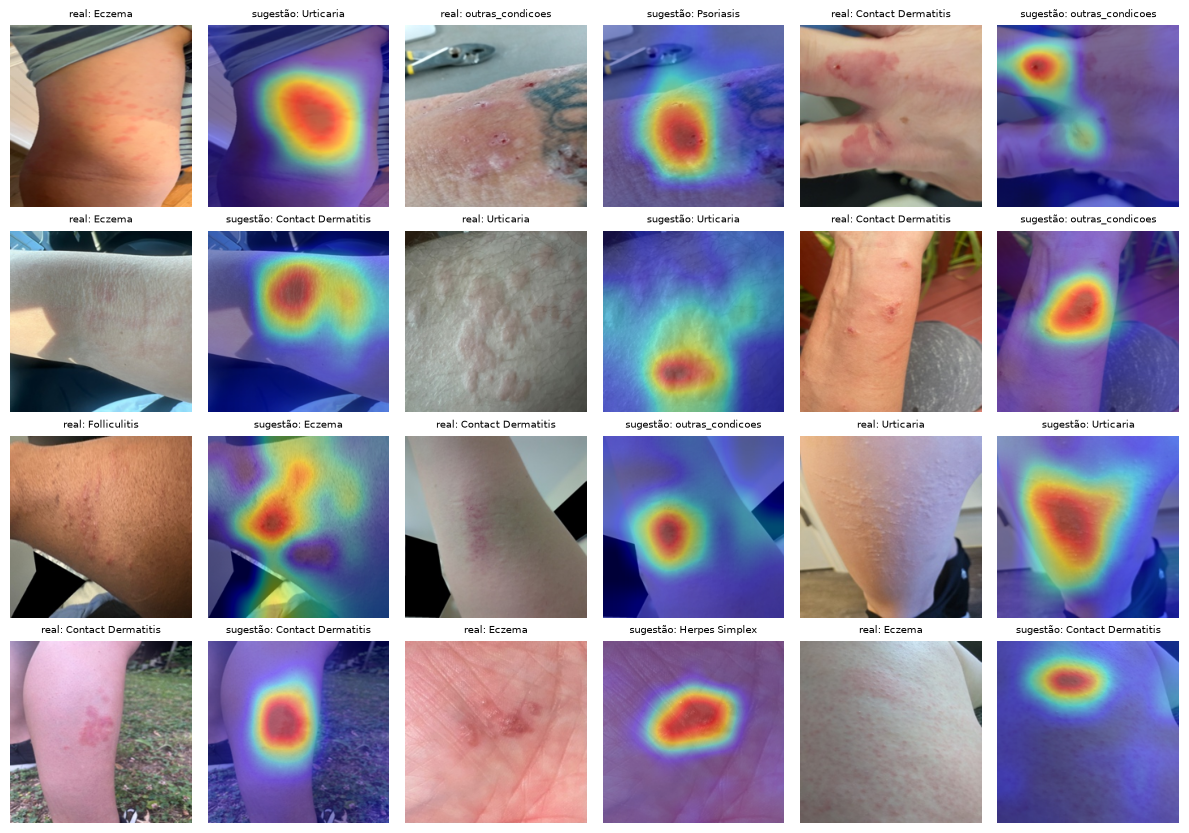

In [41]:
plot_grad_cam(teste_esp, probs_esp)

# Registro de iterações da triagem

## Iteração 3: triagem em duas etapas (09/11/2026)

*Medida ainda com os pesos da iteração 1 na rota de dermatoscopia; os valores atuais estão na iteração 4.*

**Configuração**: SCIN (25 de 26 arquivos; 2.581 casos limpos) e PAD-UFES-20 (2.283 imagens). EfficientNetV2-B0, 224 px, na CPU, em ~2h30. Detector de modalidade só com a cabeça; roteador e especialista com ajuste fino, peso por classe, calibração e limiar de confiança na validação.

| | Métrica no teste | Valor |
|---|---|---|
| Detector de modalidade | acurácia balanceada | 98,6% |
| Roteador | acurácia balanceada | 96,8% |
| Roteador | pintas do SCIN reconhecidas (teste externo) | **5,7%** |
| Especialista (17 classes) | acerto top-1 / top-3 | 28,3% / 69,2% |
| Especialista | acurácia balanceada / F1 macro / AUROC | 17,0% / 18,2% / 0,81 |
| Sistema | erro grave (🟢 quando precisava de 🟠 ou 🔴) | **12,2%** (SCIN: 31,8%) |

**Observações**
- O roteador aprendeu mais a origem da foto do que o tipo de lesão: acerta quase tudo dentro das bases e falha nas pintas do SCIN.
- Sem classes de queimadura e ferida (4 e 30 casos).
- Falta o arquivo `train-00000-of-00026.parquet` do SCIN (~4% da base).

**Próximos passos**
1. **Reduzir o erro grave**: somar a probabilidade das condições que pedem consulta e escolher na validação um limiar de alta sensibilidade, como na triagem de pintas (a medir em um teste novo, já que este foi usado).
2. **Fotos caseiras de pintas** de outras fontes, para o roteador não aprender a origem.
3. **Bases específicas** de queimaduras e feridas.
4. **Mais dados e resolução maior** para o especialista, e o arquivo que falta do SCIN.
5. **Revisão das orientações por um profissional de saúde.**

## Atualização: modelo de pintas unificado (09/11/2026)

A rota de pintas passou a usar `modelos/pintas/melhor.keras`, do notebook principal.

**Efeito na triagem**

| | Erro grave | Excesso de cautela |
|---|---|---|
| Dermatoscopia, antes | 4,2% (13 de 307) | 27,3% |
| **Dermatoscopia, agora** | **8,5% (26 de 307)** | **17,4%** |
| Sistema inteiro, antes | 12,2% (106 de 868) | 37,7% |
| **Sistema inteiro, agora** | **13,7% (119 de 868)** | **31,1%** |

PAD-UFES (0,4%) e SCIN (31,8%) não mudam: a urgência nessas rotas não depende do modelo de pintas.

PAD-UFES (0,4%) e SCIN (31,8%) não mudam: a urgência nessas rotas não depende do modelo de pintas.